In [1]:
# =============================================================================
# Assignment # 01  -  Data Science Tools & Techniques (MS DS)
# Q#1: Data Pre-processing and Exploratory Data Analysis
#
# Name    : Taha Abbas Naqvi
# Roll No : 261-8004
# Class   : MS (DS)
# Section : A
#
# Dataset 1 : Census-Income (KDD), UCI ML Repository id 117
# Dataset 2 : The Attached Dataset (csv file provided with the assignment)
#
# Layout of this notebook:
#   Part A : Dataset 2 -> EDA before cleaning, issue list, cleaning, EDA after
#   Part B : Dataset 1 -> same sequence
#   Part C : both datasets compared before vs after, cleaned files written out
#
# Each dataset is cleaned on a copy, so the raw frame stays in memory and the
# before/after comparison at the end is done on real numbers, not from notes.
# =============================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("seaborn:", sns.__version__)

pandas : 3.0.5
numpy  : 2.5.3
seaborn: 0.13.2


In [2]:
# -----------------------------------------------------------------------------
# Helper functions. The same ones are called before and after cleaning so that
# the two EDA passes are directly comparable.
# -----------------------------------------------------------------------------

def numeric_cols(df):
    return [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]


def categorical_cols(df):
    return [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]


def missing_report(df):
    # per column: how many values are missing, and what the column looks like
    n_missing = df.isna().sum()
    rep = pd.DataFrame({
        "n_missing": n_missing,
        "pct_missing": (100 * n_missing / len(df)).round(2),
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(dropna=True),
    })
    return rep.sort_values("n_missing", ascending=False)


def quality_overview(df, name):
    # one column of numbers that describes the overall state of a dataframe
    cells = df.shape[0] * df.shape[1]
    summary = pd.Series({
        "rows": df.shape[0],
        "columns": df.shape[1],
        "numeric_columns": len(numeric_cols(df)),
        "categorical_columns": len(categorical_cols(df)),
        "duplicate_rows": int(df.duplicated().sum()),
        "cells_missing": int(df.isna().sum().sum()),
        "pct_cells_missing": round(100 * df.isna().sum().sum() / cells, 3),
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1),
    }, name=name)
    return summary.to_frame()


def numeric_summary(df, cols=None):
    # describe() plus skew and kurtosis, which is what shows the outlier problem
    cols = cols or numeric_cols(df)
    desc = df[cols].describe().T
    desc["skew"] = df[cols].skew()
    desc["kurtosis"] = df[cols].kurtosis()
    return desc


def plot_numeric_distributions(df, cols, title, bins=30, ncols=4, kde=True):
    cols = [c for c in cols if c in df.columns]
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.0 * ncols, 2.9 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        sns.histplot(df[col].dropna(), bins=bins, kde=kde, ax=ax, color="#4C72B0")
        ax.set_title(f"{col}  (skew={df[col].skew():.2f})")
        ax.set_xlabel("")
    for ax in axes[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13, y=1.002)
    fig.tight_layout()
    plt.show()


def plot_boxplots(df, cols, title, ncols=4):
    cols = [c for c in cols if c in df.columns]
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        sns.boxplot(x=df[col].dropna(), ax=ax, color="#DD8452", fliersize=2)
        ax.set_title(col)
        ax.set_xlabel("")
    for ax in axes[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13, y=1.003)
    fig.tight_layout()
    plt.show()


def plot_categorical_counts(df, cols, title, top=10, ncols=3):
    # missing values are plotted as their own bar, otherwise they stay invisible
    cols = [c for c in cols if c in df.columns]
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.0 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        vc = df[col].astype("object").where(df[col].notna(), "(missing)").value_counts().head(top)
        sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color="#55A868")
        ax.set_title(f"{col}  ({df[col].nunique()} levels)")
        ax.set_xlabel("count")
    for ax in axes[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=13, y=1.002)
    fig.tight_layout()
    plt.show()


def plot_correlation(df, cols, title, figsize=(9, 7)):
    cols = [c for c in cols if c in df.columns]
    corr = df[cols].corr()
    plt.figure(figsize=figsize)
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=len(cols) <= 12,
                fmt=".2f", linewidths=.4, cbar_kws={"shrink": .8})
    plt.title(title)
    plt.tight_layout()
    plt.show()


def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


def outlier_report(df, cols, k=1.5):
    # Tukey rule: anything outside Q1-1.5*IQR .. Q3+1.5*IQR is flagged
    rows = []
    for c in cols:
        s = df[c].dropna()
        if s.empty:
            continue
        lo, hi = iqr_bounds(s, k)
        rows.append({"column": c, "lower_fence": lo, "upper_fence": hi,
                     "n_below": int((s < lo).sum()), "n_above": int((s > hi).sum()),
                     "pct_outliers": round(100 * ((s < lo) | (s > hi)).mean(), 2)})
    return pd.DataFrame(rows).sort_values("pct_outliers", ascending=False)


print("helper functions loaded")

helper functions loaded


In [3]:
# =============================================================================
# PART A - DATASET 2 (the attached csv)
# 5050 rows, 20 columns: demographics, employment, finance and health fields.
# Loaded with no cleaning arguments on purpose (no na_values, no dtype hints)
# so the raw problems are visible in the EDA below.
# =============================================================================

CSV_PATH = "Taha Naqvi - The Attached Dataset 2.csv"

df2_raw = pd.read_csv(CSV_PATH)
print("raw shape:", df2_raw.shape)
df2_raw.head(10)

raw shape: (5050, 20)


,id,age,gender,education,marital_status,workclass,occupation,hours_per_week,capital_gain,capital_loss,native_country,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk
0,1,63,Female,Masters,Married,Unemployed,Other-service,57,28219,7604,us,80471,denied,26,1,21.100,occasional,medium,759,0
1,2,20,Female,PhD,Married,Government,NaN,98,26959,8738,NaN,83789,approved,34,3,23.900,smoker,low,730,0
2,3,46,Female,Bachelors,Divorced,Unemployed,Tech-support,8,15621,7180,India,93380,approved,5,4,28.400,non-smoker,low,460,0
3,4,52,Other,Masters,Single,Government,Other-service,9,26022,8588,us,41035,denied,19,5,26.600,occasional,medium,464,0
4,5,56,Female,Masters,Single,Self-Employed,Prof-specialty,49,3075,2399,UK,69893,denied,19,1,24.500,smoker,high,NaN,0
5,6,35,Female,PhD,Divorced,Private,Tech-support,80,12092,2280,Mexico,111543,denied,0,1,24.900,occasional,high,323,1
6,7,37,Male,PhD,Divorced,Government,Tech-support,65,28343,9356,USA,66828,denied,28,4,33.000,non-smoker,medium,485,0
7,8,60,Male,Bachelors,Widowed,Unemployed,Exec-managerial,41,43788,1951,Canada,38590,denied,2,2,32.800,occasional,high,615,0
8,9,40,Female,Masters,Married,Private,Other-service,35,8495,522,us,62033,approved,8,3,32.300,occasional,medium,456,0
9,10,51,Male,Bachelors,Single,Government,Machine-op-inspct,41,47716,3620,Germany,62193,approved,40,3,25.000,smoker,low,766,0


In [4]:
# --- A.1 EDA BEFORE CLEANING: structure and dtypes ---------------------------
print(df2_raw.info())
quality_overview(df2_raw, "Dataset 2 - RAW")

<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5050 non-null   int64  
 1   age                5050 non-null   int64  
 2   gender             5050 non-null   str    
 3   education          5050 non-null   str    
 4   marital_status     5050 non-null   str    
 5   workclass          4798 non-null   str    
 6   occupation         4798 non-null   str    
 7   hours_per_week     5050 non-null   int64  
 8   capital_gain       5050 non-null   int64  
 9   capital_loss       5050 non-null   int64  
 10  native_country     4796 non-null   str    
 11  annual_income      4799 non-null   str    
 12  loan_status        5050 non-null   str    
 13  experience_years   5050 non-null   int64  
 14  job_satisfaction   5050 non-null   int64  
 15  bmi                4800 non-null   float64
 16  smoking_status     5050 non-null   

,Dataset 2 - RAW
rows,"5,050.000"
columns,20.000
numeric_columns,9.000
categorical_columns,11.000
duplicate_rows,49.000
cells_missing,"1,509.000"
pct_cells_missing,1.494
memory_MB,3.400


,n_missing,pct_missing,dtype,n_unique
native_country,254,5.030,str,8
workclass,252,4.990,str,4
occupation,252,4.990,str,7
annual_income,251,4.970,str,4522
credit_score,250,4.950,str,551
bmi,250,4.950,float64,309
age,0,0.000,int64,52
id,0,0.000,int64,5000
education,0,0.000,str,4
gender,0,0.000,str,3


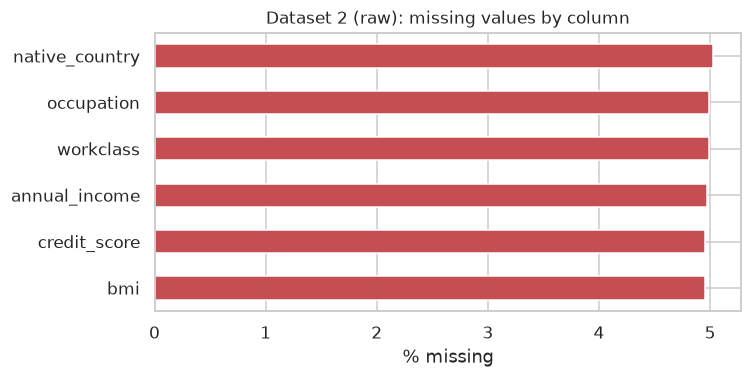

In [5]:
# --- A.2 missing values ------------------------------------------------------
miss2_before = missing_report(df2_raw)
display(miss2_before)

ax = miss2_before.loc[miss2_before.n_missing > 0, "pct_missing"].sort_values().plot(
    kind="barh", figsize=(7, 3.6), color="#C44E52")
ax.set_xlabel("% missing")
ax.set_title("Dataset 2 (raw): missing values by column")
plt.tight_layout()
plt.show()

In [6]:
# --- A.3 summary statistics, numeric columns ---------------------------------
# annual_income and credit_score are missing from this table because pandas read
# them as text. That already points to problem number 1 (see the issue list).
numeric_summary(df2_raw)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
id,"5,050.000","2,498.039","1,444.698",1.000,"1,244.250","2,497.500","3,748.750","5,000.000",0.002,-1.201
age,"5,050.000",43.619,14.943,18.000,31.000,43.500,57.000,69.000,-0.006,-1.184
hours_per_week,"5,050.000",53.851,33.205,5.000,29.000,54.000,77.000,391.000,2.719,23.394
capital_gain,"5,050.000","25,520.049","14,473.177",3.000,"13,292.250","25,933.000","37,748.500","49,994.000",-0.041,-1.182
capital_loss,"5,050.000","4,935.995","2,919.034",0.000,"2,381.250","4,925.500","7,461.750","9,998.000",0.028,-1.228
experience_years,"5,050.000",21.974,12.863,0.000,11.000,22.000,33.000,44.000,0.011,-1.189
job_satisfaction,"5,050.000",3.010,1.419,1.000,2.000,3.000,4.000,5.000,-0.015,-1.307
bmi,"4,800.000",27.446,8.228,9.200,23.700,27.100,30.500,204.000,9.036,138.397
disease_risk,"5,050.000",0.311,0.463,0.000,0.000,0.000,1.000,1.000,0.815,-1.336


In [7]:
# --- A.4 summary statistics, text columns ------------------------------------
cat2_before = categorical_cols(df2_raw)
print("columns parsed as text:", cat2_before)

pd.DataFrame({
    "n_unique": df2_raw[cat2_before].nunique(),
    "n_missing": df2_raw[cat2_before].isna().sum(),
    "top_value": [df2_raw[c].mode(dropna=True).iloc[0] for c in cat2_before],
    "levels": [", ".join(map(str, sorted(df2_raw[c].dropna().unique())[:10])) for c in cat2_before],
})

columns parsed as text: ['gender', 'education', 'marital_status', 'workclass', 'occupation', 'native_country', 'annual_income', 'loan_status', 'smoking_status', 'physical_activity', 'credit_score']


,n_unique,n_missing,top_value,levels
gender,3,0,Female,"Female, Male, Other"
education,4,0,PhD,"Bachelors, High School, Masters, PhD"
marital_status,4,0,Divorced,"Divorced, Married, Single, Widowed"
workclass,4,252,Unemployed,"Government, Private, Self-Employed, Unemployed"
occupation,7,252,Sales,"Craft-repair, Exec-managerial, Machine-op-insp..."
native_country,8,254,UK,"Canada, Germany, India, Mexico, U.S., UK, USA, us"
annual_income,4522,251,unknown,"-10469, -12996, -17312, -17592, -18187, -2096,..."
loan_status,2,0,approved,"approved, denied"
smoking_status,3,0,smoker,"non-smoker, occasional, smoker"
physical_activity,3,0,high,"high, low, medium"


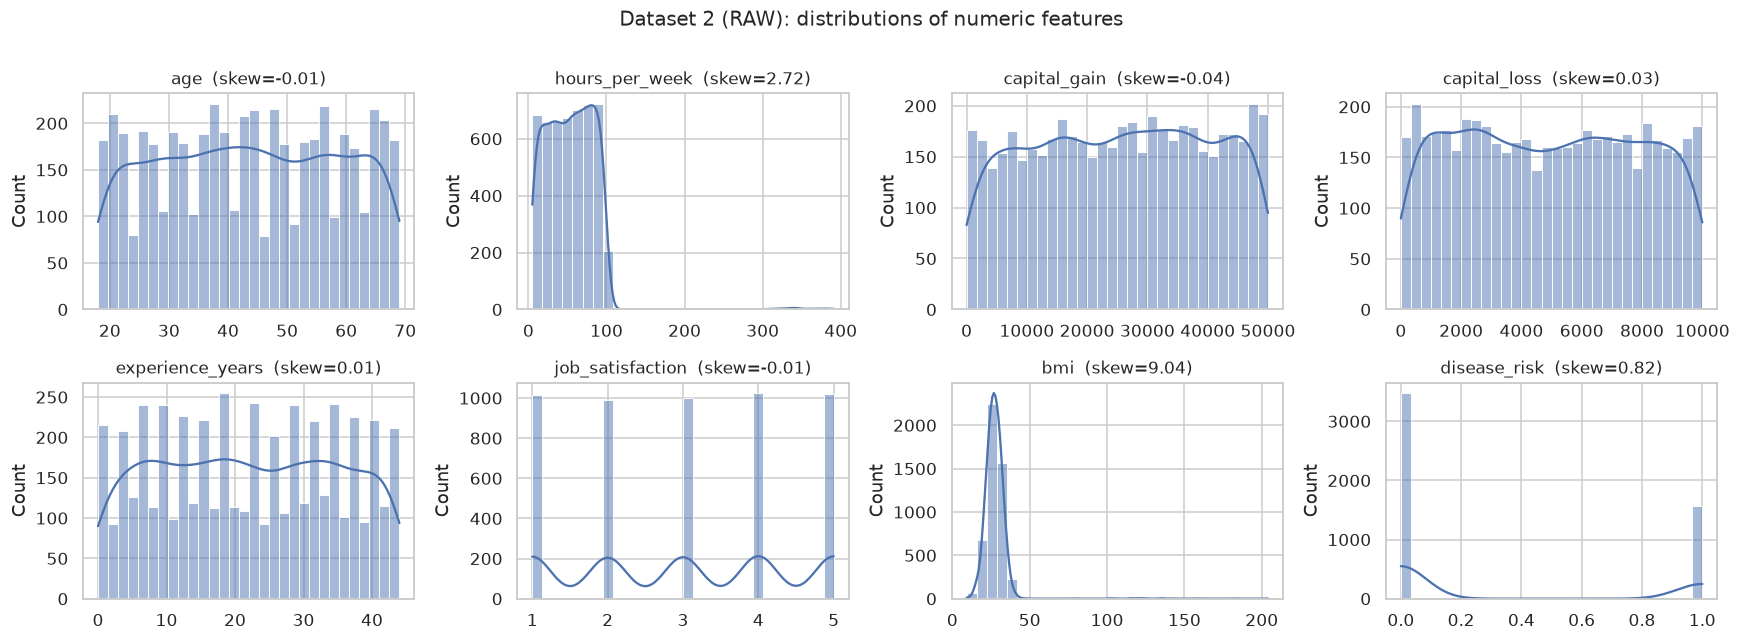

In [8]:
# --- A.5 distribution plots --------------------------------------------------
num2_raw = numeric_cols(df2_raw)
plot_numeric_distributions(df2_raw, [c for c in num2_raw if c != "id"],
                           "Dataset 2 (RAW): distributions of numeric features")

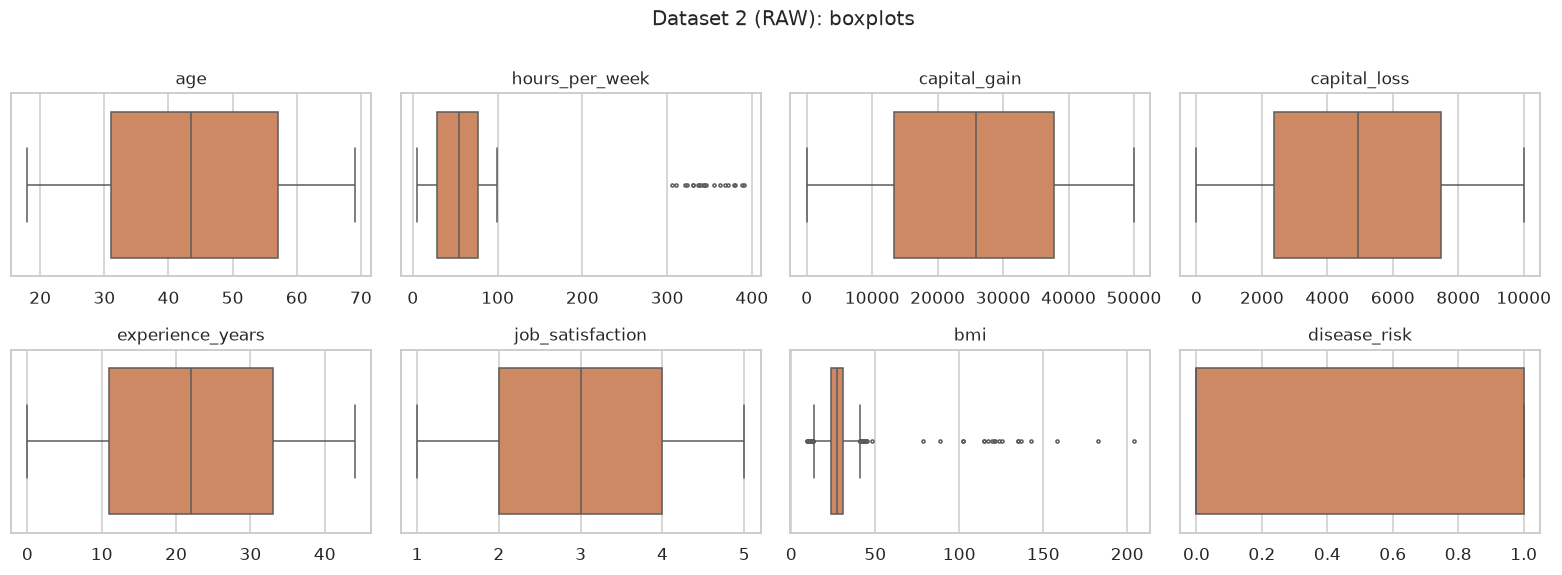

In [9]:
# --- A.6 boxplots, to see the outliers ---------------------------------------
plot_boxplots(df2_raw, [c for c in num2_raw if c != "id"],
              "Dataset 2 (RAW): boxplots")

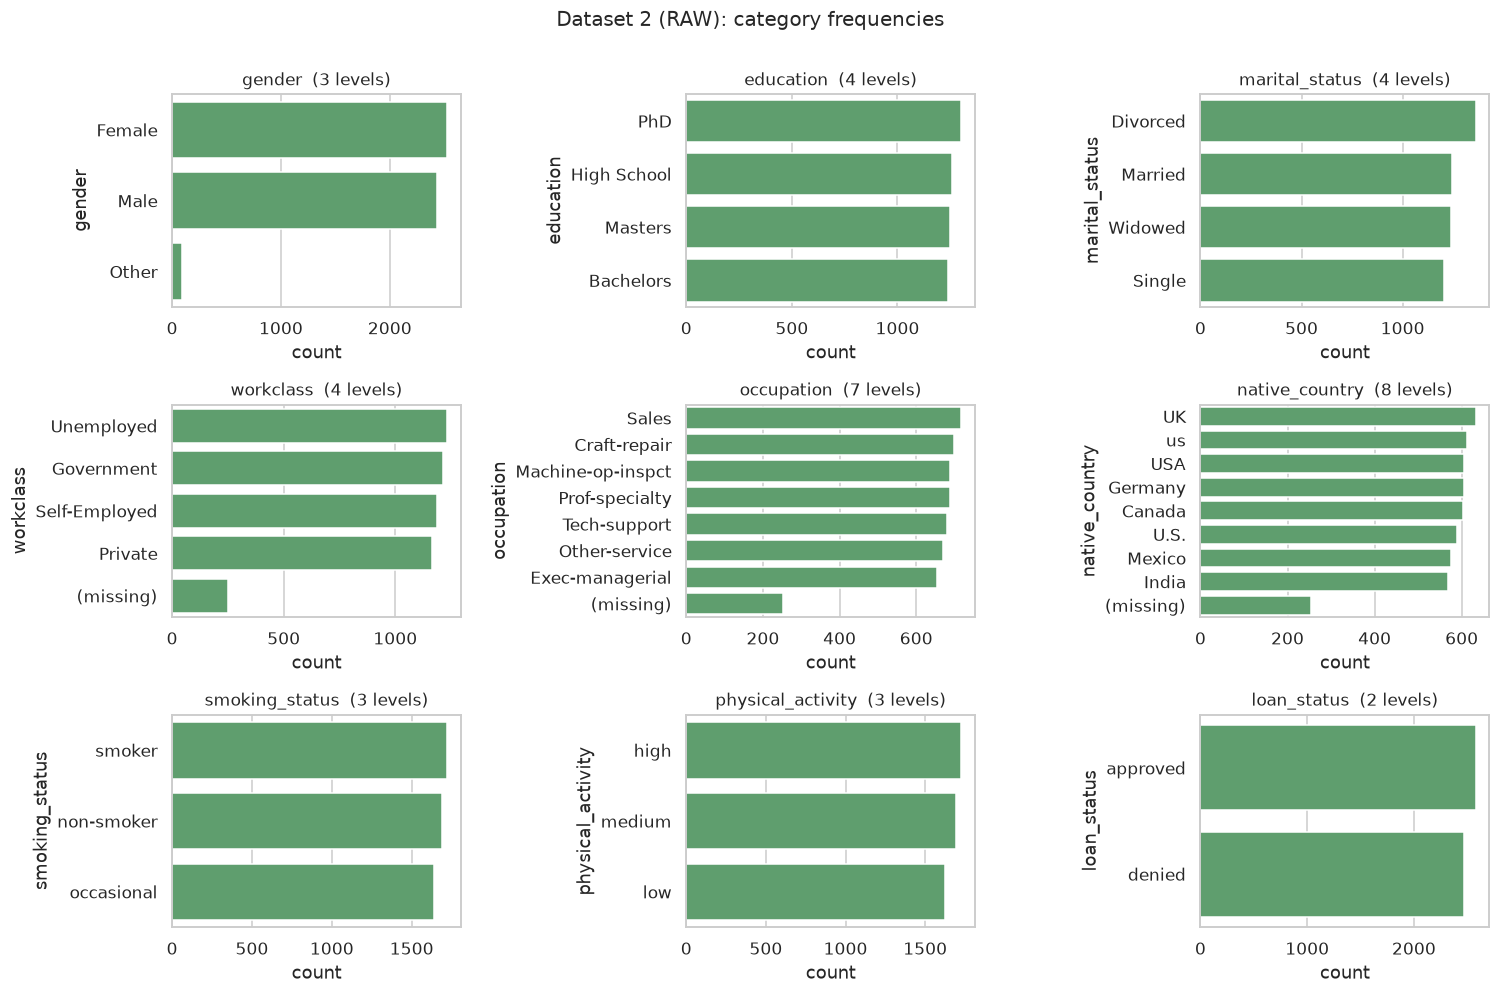

In [10]:
# --- A.7 category frequencies ------------------------------------------------
plot_categorical_counts(df2_raw, ["gender", "education", "marital_status", "workclass",
                                  "occupation", "native_country", "smoking_status",
                                  "physical_activity", "loan_status"],
                        "Dataset 2 (RAW): category frequencies")

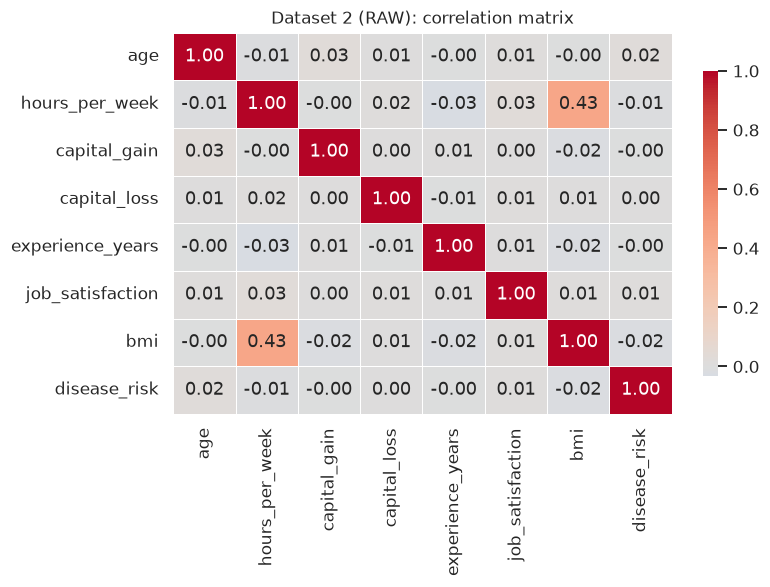

In [11]:
# --- A.8 correlation between the raw numeric columns -------------------------
plot_correlation(df2_raw, [c for c in num2_raw if c != "id"],
                 "Dataset 2 (RAW): correlation matrix", figsize=(7.5, 5.5))

In [12]:
# =============================================================================
# A.9 ISSUES FOUND IN DATASET 2  (Task 1, part 1)
#
#  1. "unknown" used as a missing marker in annual_income and credit_score
#     (101 cells each). Because of it both columns were read as text.
#     -> replace with NaN and convert the columns to numeric
#  2. Real NaN values in 6 columns, about 5% each.
#     -> median for numeric columns, mode for categorical ones
#  3. Duplicates: 49 identical rows and 50 repeated id values.
#     -> drop, keep the first copy
#  4. native_country stores the same country as us / USA / U.S.
#     -> map all three to one label
#  5. Impossible values: hours_per_week above 168 (a week has 168 hours),
#     bmi up to 204 and as low as 9.2, 12 negative salaries.
#     -> set them to NaN and impute them with the rest
#  6. annual_income is extremely right skewed (max 2.29 million, skew 16).
#     -> cap at the 1st and 99th percentile
#  7. experience_years is larger than age-16 for 1939 rows, which is not
#     possible. -> cap at age-16 and keep a flag column
#  8. id is just a row number, it carries no information. -> drop
#  9. Feature ranges differ by 4 orders of magnitude. -> standardise
# 10. 9 text columns cannot be used by a model as they are. -> encode
# 11. disease_risk is 68.9% / 31.1%, so mildly imbalanced. Noted for the
#     modelling stage (stratified split or class weights), not fixed here.
#
# The cell below prints the evidence for each of these points.
# =============================================================================

print("1) sentinel value 'unknown':")
for c in ["annual_income", "credit_score"]:
    print(f"   {c:14s} dtype={str(df2_raw[c].dtype):8s} "
          f"count of 'unknown' = {(df2_raw[c] == 'unknown').sum()}")

print("\n2) missing values per column:")
print(df2_raw.isna().sum()[lambda s: s > 0].to_string())

print("\n3) duplicates:")
print("   identical rows   :", df2_raw.duplicated().sum())
print("   repeated id value:", df2_raw["id"].duplicated().sum())

print("\n4) native_country levels:")
print(df2_raw["native_country"].value_counts(dropna=False).to_string())

inc_num = pd.to_numeric(df2_raw["annual_income"], errors="coerce")
print("\n5) impossible values:")
print("   hours_per_week > 168 :", (df2_raw["hours_per_week"] > 168).sum(),
      "| max =", df2_raw["hours_per_week"].max())
print("   bmi > 60 or < 12     :", ((df2_raw["bmi"] > 60) | (df2_raw["bmi"] < 12)).sum(),
      "| range =", (df2_raw["bmi"].min(), df2_raw["bmi"].max()))
print("   annual_income < 0    :", (inc_num < 0).sum(), "| min =", inc_num.min())

print("\n6) skew of annual_income:", round(inc_num.skew(), 2), "| max =", f"{inc_num.max():,.0f}")

print("\n7) rows where experience_years > age - 16 :",
      (df2_raw["experience_years"] > df2_raw["age"] - 16).sum())

print("\n11) target balance, disease_risk:")
print((df2_raw["disease_risk"].value_counts(normalize=True) * 100).round(1).to_string())

1) sentinel value 'unknown':
   annual_income  dtype=str      count of 'unknown' = 101
   credit_score   dtype=str      count of 'unknown' = 101

2) missing values per column:
workclass         252
occupation        252
native_country    254
annual_income     251
bmi               250
credit_score      250

3) duplicates:
   identical rows   : 49
   repeated id value: 50

4) native_country levels:
native_country
UK         632
us         613
USA        606
Germany    606
Canada     604
U.S.       590
Mexico     576
India      569
NaN        254

5) impossible values:
   hours_per_week > 168 : 20 | max = 391
   bmi > 60 or < 12     : 26 | range = (np.float64(9.2), np.float64(204.0))
   annual_income < 0    : 12 | min = -21818.0

6) skew of annual_income: 16.09 | max = 2,292,645

7) rows where experience_years > age - 16 : 1939

11) target balance, disease_risk:
disease_risk
0   68.900
1   31.100


In [13]:
# =============================================================================
# A.10 CLEANING DATASET 2  (Task 1, part 2)
# Order of the steps matters. Invalid values are removed before anything is
# imputed, otherwise the medians would be pulled towards the corrupt values.
# =============================================================================

df2 = df2_raw.copy()
log2 = []


def step(msg, frame=None):
    # keeps a numbered record of what was done, printed again at the end
    shape = f"{frame.shape}" if frame is not None else ""
    log2.append(msg)
    print(f"[{len(log2):02d}] {msg}   {shape}")

In [14]:
# --- step 1: sentinel strings to NaN, then fix the dtypes --------------------
SENTINELS = ["unknown", "Unknown", "UNKNOWN", "?", "N/A", "n/a", "NA", "na", "None", "", "-"]

for c in categorical_cols(df2):
    df2[c] = df2[c].astype("object").str.strip()      # remove stray spaces first
df2 = df2.replace(SENTINELS, np.nan)

for c in ["annual_income", "credit_score"]:
    df2[c] = pd.to_numeric(df2[c], errors="coerce")

step("sentinel strings to NaN, annual_income and credit_score converted to numeric", df2)
print(df2[["annual_income", "credit_score"]].dtypes)
print("missing now:", df2[["annual_income", "credit_score"]].isna().sum().to_dict())

[01] sentinel strings to NaN, annual_income and credit_score converted to numeric   (5050, 20)
annual_income    float64
credit_score     float64
dtype: object
missing now: {'annual_income': 352, 'credit_score': 351}


In [15]:
# --- step 2: duplicates ------------------------------------------------------
before = len(df2)
df2 = df2.drop_duplicates(keep="first")                 # fully identical rows
df2 = df2.drop_duplicates(subset="id", keep="first")    # same id used twice
step(f"dropped {before - len(df2)} duplicate rows", df2)

[02] dropped 50 duplicate rows   (5000, 20)


In [16]:
# --- step 3: inconsistent country labels -------------------------------------
COUNTRY_MAP = {"us": "United-States", "USA": "United-States", "U.S.": "United-States",
               "U.S": "United-States", "United States": "United-States",
               "UK": "United-Kingdom"}
df2["native_country"] = df2["native_country"].replace(COUNTRY_MAP)
step("native_country labels standardised", df2)
print(df2["native_country"].value_counts(dropna=False).to_string())

[03] native_country labels standardised   (5000, 20)
native_country
United-States     1791
United-Kingdom     624
Canada             599
Germany            599
Mexico             571
India              566
NaN                250


In [17]:
# --- step 4: values that are outside a sensible range ------------------------
# These are treated as missing rather than deleted, so no row is lost.
rules = {
    "hours_per_week": (df2["hours_per_week"] <= 0) | (df2["hours_per_week"] > 168),
    "bmi":            (df2["bmi"] < 12) | (df2["bmi"] > 60),
    "annual_income":  df2["annual_income"] < 0,
    "credit_score":   (df2["credit_score"] < 300) | (df2["credit_score"] > 850),
    "age":            (df2["age"] < 16) | (df2["age"] > 100),
}
for col, mask in rules.items():
    n = int(mask.sum())
    if n:
        df2.loc[mask, col] = np.nan
    print(f"   {col:15s} -> {n:4d} invalid value(s) set to NaN")

# nobody can start working before the age of 16, so experience is capped there
inconsistent = df2["experience_years"] > (df2["age"] - 16)
df2["experience_flag"] = inconsistent.astype(int)
df2.loc[inconsistent, "experience_years"] = (df2.loc[inconsistent, "age"] - 16).clip(lower=0)
print(f"   experience_years-> {int(inconsistent.sum()):4d} row(s) capped at age-16, "
      f"marked in experience_flag")

inc_valid = df2["annual_income"].copy()   # saved for the skew comparison below
step("range and consistency rules applied", df2)

   hours_per_week  ->   20 invalid value(s) set to NaN
   bmi             ->   26 invalid value(s) set to NaN
   annual_income   ->   12 invalid value(s) set to NaN
   credit_score    ->    0 invalid value(s) set to NaN
   age             ->    0 invalid value(s) set to NaN
   experience_years-> 1926 row(s) capped at age-16, marked in experience_flag
[04] range and consistency rules applied   (5000, 21)


In [18]:
# --- step 5: outliers --------------------------------------------------------
num2 = [c for c in numeric_cols(df2) if c not in ("id", "disease_risk", "experience_flag")]
display(outlier_report(df2, num2))

# Capping at the 1st/99th percentile instead of deleting rows, so the extreme
# tail stops dominating the mean and the scaler but the rows are still there.
skewed = ["annual_income", "capital_gain", "capital_loss"]
caps = {}
for c in skewed:
    lo, hi = df2[c].quantile([0.01, 0.99])
    caps[c] = (lo, hi)
    df2[c] = df2[c].clip(lo, hi)
print("\ncaps used (1st / 99th percentile):")
for c, (lo, hi) in caps.items():
    print(f"   {c:15s} [{lo:,.0f} , {hi:,.0f}]")

# A log transform is the usual alternative here, so both were compared before
# deciding. Capping alone already gives a skew near zero, and log1p pushes the
# distribution too far the other way, so no log column is added.
skew_cmp2 = pd.Series({
    "raw (invalid removed)": inc_valid.skew(),
    "log1p(raw)":            np.log1p(inc_valid.clip(lower=0)).skew(),
    "capped 1/99":           df2["annual_income"].skew(),
    "log1p(capped)":         np.log1p(df2["annual_income"]).skew(),
}).round(2)
print("\nskew of annual_income under each option:")
print(skew_cmp2.to_string())
step("outliers capped at the 1/99 percentile", df2)

,column,lower_fence,upper_fence,n_below,n_above,pct_outliers
4,annual_income,"2,016.750","139,450.750",8,40,1.030
7,bmi,13.500,40.700,8,15,0.490
0,age,-8.000,96.000,0,0,0.000
2,capital_gain,"-23,398.000","74,444.000",0,0,0.000
1,hours_per_week,-43.000,149.000,0,0,0.000
3,capital_loss,"-5,206.375","15,072.625",0,0,0.000
5,experience_years,-18.500,49.500,0,0,0.000
6,job_satisfaction,-1.000,7.000,0,0,0.000
8,credit_score,27.000,"1,131.000",0,0,0.000



caps used (1st / 99th percentile):
   annual_income   [11,707 , 134,961]
   capital_gain    [483 , 49,618]
   capital_loss    [110 , 9,902]

skew of annual_income under each option:
raw (invalid removed)   16.070
log1p(raw)              -1.550
capped 1/99              0.080
log1p(capped)           -1.310
[05] outliers capped at the 1/99 percentile   (5000, 21)


In [19]:
# --- step 6: imputation ------------------------------------------------------
# median for the numeric columns because they are still skewed, mode for the
# categorical ones.
num_to_impute = [c for c in numeric_cols(df2) if df2[c].isna().any()]
cat_to_impute = [c for c in categorical_cols(df2) if df2[c].isna().any()]
print("numeric columns to impute    :", num_to_impute)
print("categorical columns to impute:", cat_to_impute)

if num_to_impute:
    df2[num_to_impute] = SimpleImputer(strategy="median").fit_transform(df2[num_to_impute])
if cat_to_impute:
    df2[cat_to_impute] = SimpleImputer(strategy="most_frequent").fit_transform(df2[cat_to_impute])

step(f"imputed {len(num_to_impute)} numeric (median) and {len(cat_to_impute)} categorical (mode) columns", df2)
print("missing cells left:", int(df2.isna().sum().sum()))

numeric columns to impute    : ['hours_per_week', 'annual_income', 'bmi', 'credit_score']
categorical columns to impute: ['workclass', 'occupation', 'native_country']
[06] imputed 4 numeric (median) and 3 categorical (mode) columns   (5000, 21)
missing cells left: 0


In [20]:
# --- step 7: encoding of the categorical features ----------------------------
# Three methods, picked according to what the variable actually is:
#   ordinal  -> education, smoking_status, physical_activity. These have a real
#               order, so an integer code keeps that information in one column.
#   binary   -> loan_status. Two levels only, one column is enough.
#   one-hot  -> gender, marital_status, workclass, occupation, native_country.
#               No order between the levels. drop_first=True avoids the dummy
#               variable trap (the dropped level becomes the reference).
# job_satisfaction is already an ordinal 1-5 integer, so it is left as it is.

df2_enc = df2.drop(columns=["id"]).copy()

ORDINAL_MAPS = {
    "education":         ["High School", "Bachelors", "Masters", "PhD"],
    "smoking_status":    ["non-smoker", "occasional", "smoker"],
    "physical_activity": ["low", "medium", "high"],
}
ord_cols = list(ORDINAL_MAPS)
ord_enc = OrdinalEncoder(categories=[ORDINAL_MAPS[c] for c in ord_cols])
df2_enc[ord_cols] = ord_enc.fit_transform(df2_enc[ord_cols]).astype(int)
for c in ord_cols:
    print(f"   ordinal  {c:18s}: {dict(zip(ORDINAL_MAPS[c], range(len(ORDINAL_MAPS[c]))))}")

df2_enc["loan_status"] = (df2_enc["loan_status"] == "approved").astype(int)
print("   binary   loan_status       : denied=0, approved=1")

nominal = ["gender", "marital_status", "workclass", "occupation", "native_country"]
df2_enc = pd.get_dummies(df2_enc, columns=nominal, drop_first=True, dtype=int)
print("   one-hot  ", nominal)

step(f"encoding done, {df2.shape[1]-1} columns became {df2_enc.shape[1]}", df2_enc)
df2_enc.head()

   ordinal  education         : {'High School': 0, 'Bachelors': 1, 'Masters': 2, 'PhD': 3}
   ordinal  smoking_status    : {'non-smoker': 0, 'occasional': 1, 'smoker': 2}
   ordinal  physical_activity : {'low': 0, 'medium': 1, 'high': 2}
   binary   loan_status       : denied=0, approved=1
   one-hot   ['gender', 'marital_status', 'workclass', 'occupation', 'native_country']
[07] encoding done, 20 columns became 34   (5000, 34)


,age,education,hours_per_week,capital_gain,capital_loss,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk,experience_flag,gender_Male,gender_Other,marital_status_Married,marital_status_Single,marital_status_Widowed,workclass_Private,workclass_Self-Employed,workclass_Unemployed,occupation_Exec-managerial,occupation_Machine-op-inspct,occupation_Other-service,occupation_Prof-specialty,occupation_Sales,occupation_Tech-support,native_country_Germany,native_country_India,native_country_Mexico,native_country_United-Kingdom,native_country_United-States
0,63,2,57.000,"28,219.000","7,604.000","80,471.000",0,26,1,21.100,1,1,759.000,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1
1,20,3,98.000,"26,959.000","8,738.000","83,789.000",1,4,3,23.900,2,0,730.000,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
2,46,1,8.000,"15,621.000","7,180.000","93,380.000",1,5,4,28.400,0,0,460.000,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0
3,52,2,9.000,"26,022.000","8,588.000","41,035.000",0,19,5,26.600,1,1,464.000,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
4,56,2,49.000,"3,075.000","2,399.000","69,893.000",0,19,1,24.500,2,2,589.000,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0


In [21]:
# --- step 8: scaling ---------------------------------------------------------
TARGET = "disease_risk"
scale_cols = ["age", "hours_per_week", "capital_gain", "capital_loss", "annual_income",
              "experience_years", "bmi", "credit_score"]

df2_clean = df2_enc.copy()
scaler2 = StandardScaler()
df2_clean[scale_cols] = scaler2.fit_transform(df2_clean[scale_cols])

step("continuous features standardised to mean 0 and sd 1", df2_clean)
df2_clean[scale_cols].describe().T[["mean", "std", "min", "max"]]

[08] continuous features standardised to mean 0 and sd 1   (5000, 34)


,mean,std,min,max
age,-0.000,1.000,-1.714,1.701
hours_per_week,0.000,1.000,-1.733,1.687
capital_gain,0.000,1.000,-1.732,1.665
capital_loss,-0.000,1.000,-1.660,1.700
annual_income,-0.000,1.000,-2.440,2.665
experience_years,-0.000,1.000,-1.480,2.486
bmi,0.000,1.000,-3.154,4.334
credit_score,-0.000,1.000,-1.821,1.747


In [22]:
# --- the full list of steps applied to dataset 2 -----------------------------
print("Dataset 2 cleaning steps")
print("-" * 60)
for i, m in enumerate(log2, 1):
    print(f"{i:2d}. {m}")
print("-" * 60)
print(f"raw   : {df2_raw.shape[0]:5d} rows x {df2_raw.shape[1]:3d} cols")
print(f"clean : {df2_clean.shape[0]:5d} rows x {df2_clean.shape[1]:3d} cols")

Dataset 2 cleaning steps
------------------------------------------------------------
 1. sentinel strings to NaN, annual_income and credit_score converted to numeric
 2. dropped 50 duplicate rows
 3. native_country labels standardised
 4. range and consistency rules applied
 5. outliers capped at the 1/99 percentile
 6. imputed 4 numeric (median) and 3 categorical (mode) columns
 7. encoding done, 20 columns became 34
 8. continuous features standardised to mean 0 and sd 1
------------------------------------------------------------
raw   :  5050 rows x  20 cols
clean :  5000 rows x  34 cols


In [23]:
# =============================================================================
# A.11 EDA AFTER CLEANING AND COMPARISON WITH THE BEFORE STATE  (Task 2)
# =============================================================================

cmp2 = pd.concat([quality_overview(df2_raw, "BEFORE"),
                  quality_overview(df2_clean, "AFTER")], axis=1)
cmp2["change"] = cmp2["AFTER"] - cmp2["BEFORE"]
cmp2

,BEFORE,AFTER,change
rows,"5,050.000","5,000.000",-50.000
columns,20.000,34.000,14.000
numeric_columns,9.000,34.000,25.000
categorical_columns,11.000,0.000,-11.000
duplicate_rows,49.000,0.000,-49.000
cells_missing,"1,509.000",0.000,"-1,509.000"
pct_cells_missing,1.494,0.000,-1.494
memory_MB,3.400,1.400,-2.000


In [24]:
# --- missing values and duplicates after cleaning ----------------------------
print("missing cells   before:", int(df2_raw.isna().sum().sum()),
      " after:", int(df2_clean.isna().sum().sum()))
print("duplicate rows  before:", int(df2_raw.duplicated().sum()),
      " after:", int(df2_clean.duplicated().sum()))
print("text columns    before:", len(categorical_cols(df2_raw)),
      " after:", len(categorical_cols(df2_clean)))
missing_report(df2_clean).head(8)

missing cells   before: 1509  after: 0
duplicate rows  before: 49  after: 0
text columns    before: 11  after: 0


,n_missing,pct_missing,dtype,n_unique
age,0,0.000,float64,52
education,0,0.000,int64,4
hours_per_week,0,0.000,float64,95
capital_gain,0,0.000,float64,4660
capital_loss,0,0.000,float64,3847
annual_income,0,0.000,float64,4417
loan_status,0,0.000,int64,2
experience_years,0,0.000,float64,45


In [25]:
# --- summary statistics after cleaning ---------------------------------------
# Shown on df2 (cleaned but not yet scaled) so the units are still readable.
numeric_summary(df2, num2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,"5,000.000",43.593,14.938,18.000,31.000,43.000,57.000,69.000,-0.003,-1.183
hours_per_week,"5,000.000",52.635,27.487,5.000,29.000,54.000,77.000,99.000,-0.050,-1.201
capital_gain,"5,000.000","25,530.120","14,464.645",482.970,"13,292.750","25,913.500","37,753.250","49,618.010",-0.040,-1.184
capital_loss,"5,000.000","4,947.748","2,914.233",109.980,"2,398.250","4,946.000","7,468.000","9,902.010",0.023,-1.229
annual_income,"5,000.000","70,614.632","24,145.516","11,707.400","54,915.250","70,040.000","86,462.000","134,961.240",0.084,0.020
experience_years,"5,000.000",16.419,11.094,0.000,7.000,15.000,24.000,44.000,0.504,-0.698
job_satisfaction,"5,000.000",3.010,1.419,1.000,2.000,3.000,4.000,5.000,-0.015,-1.307
bmi,"5,000.000",27.079,4.781,12.000,23.900,27.100,30.300,47.800,0.027,0.204
credit_score,"5,000.000",580.132,153.875,300.000,451.750,589.000,707.000,849.000,-0.077,-1.063


In [26]:
# --- the same statistics, before against after -------------------------------
key = ["age", "hours_per_week", "annual_income", "bmi", "credit_score", "experience_years"]

before_stats = df2_raw.assign(
    annual_income=pd.to_numeric(df2_raw["annual_income"], errors="coerce"),
    credit_score=pd.to_numeric(df2_raw["credit_score"], errors="coerce"))[key]

rows = []
for c in key:
    b, a = before_stats[c].dropna(), df2[c]
    rows.append({"feature": c,
                 "mean_before": b.mean(), "mean_after": a.mean(),
                 "std_before": b.std(), "std_after": a.std(),
                 "min_before": b.min(), "min_after": a.min(),
                 "max_before": b.max(), "max_after": a.max(),
                 "skew_before": b.skew(), "skew_after": a.skew(),
                 "missing_before": int(before_stats[c].isna().sum()),
                 "missing_after": int(a.isna().sum())})
pd.DataFrame(rows).set_index("feature").round(2)

,mean_before,mean_after,std_before,std_after,min_before,min_after,max_before,max_after,skew_before,skew_after,missing_before,missing_after
feature,,,,,,,,,,,,
age,43.620,43.590,14.940,14.940,18.000,18.000,69.000,69.000,-0.010,-0.000,0,0
hours_per_week,53.850,52.640,33.210,27.490,5.000,5.000,391.000,99.000,2.720,-0.050,0,0
annual_income,"74,887.790","70,614.630","82,442.850","24,145.520","-21,818.000","11,707.400","2,292,645.000","134,961.240",16.090,0.080,352,0
bmi,27.450,27.080,8.230,4.780,9.200,12.000,204.000,47.800,9.040,0.030,250,0
credit_score,579.550,580.130,159.320,153.870,300.000,300.000,849.000,849.000,-0.060,-0.080,351,0
experience_years,21.970,16.420,12.860,11.090,0.000,0.000,44.000,44.000,0.010,0.500,0,0


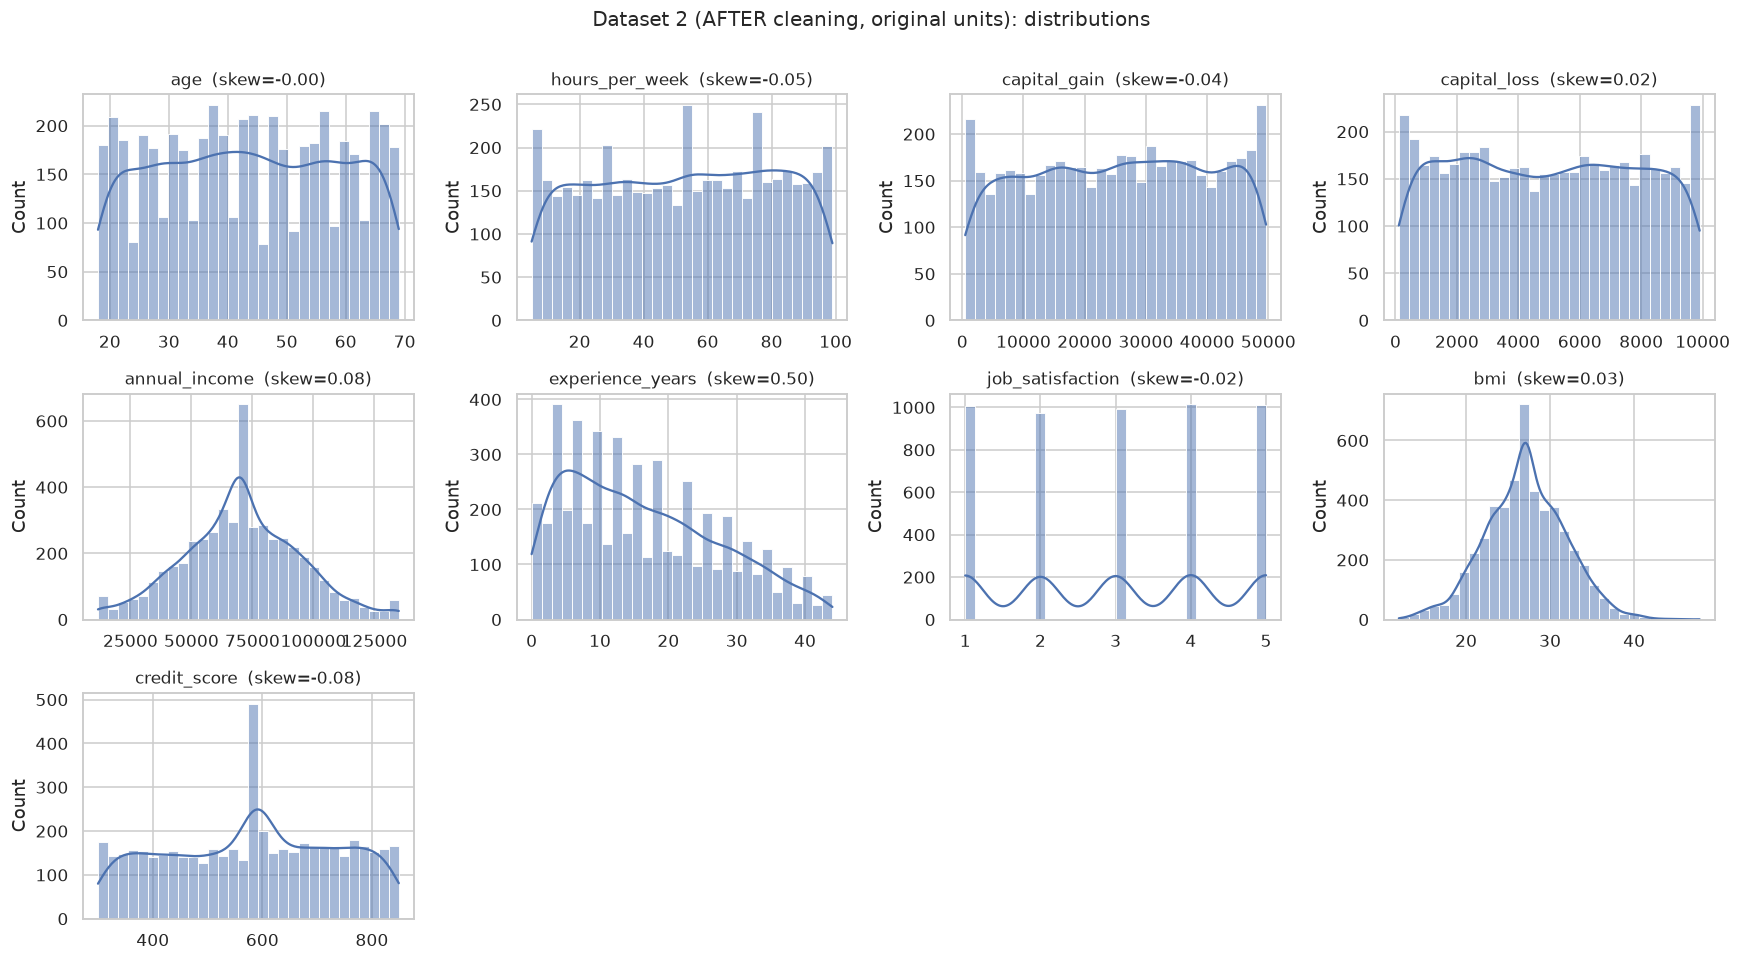

In [27]:
# --- distributions after cleaning --------------------------------------------
plot_numeric_distributions(df2, num2, "Dataset 2 (AFTER cleaning, original units): distributions")

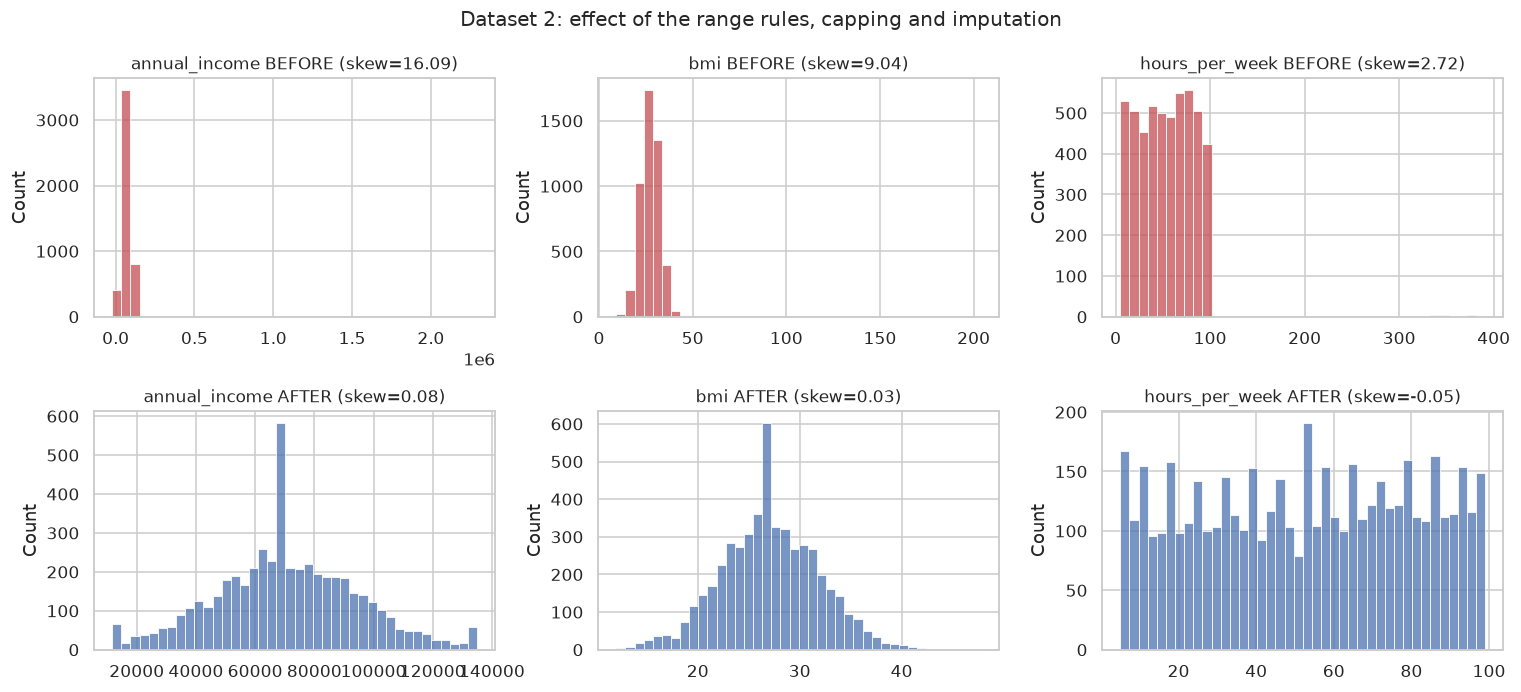

In [28]:
# --- the three worst columns, before on top and after below ------------------
pairs = [("annual_income", before_stats["annual_income"], df2["annual_income"]),
         ("bmi", df2_raw["bmi"], df2["bmi"]),
         ("hours_per_week", df2_raw["hours_per_week"], df2["hours_per_week"])]

fig, axes = plt.subplots(2, 3, figsize=(14, 6.4))
for j, (name, b, a) in enumerate(pairs):
    sns.histplot(b.dropna(), bins=40, ax=axes[0, j], color="#C44E52")
    axes[0, j].set_title(f"{name} BEFORE (skew={b.skew():.2f})")
    sns.histplot(a.dropna(), bins=40, ax=axes[1, j], color="#4C72B0")
    axes[1, j].set_title(f"{name} AFTER (skew={a.skew():.2f})")
    axes[0, j].set_xlabel("")
    axes[1, j].set_xlabel("")
fig.suptitle("Dataset 2: effect of the range rules, capping and imputation", fontsize=13)
fig.tight_layout()
plt.show()

In [29]:
# --- how many Tukey outliers are left ----------------------------------------
out_before = outlier_report(before_stats.assign(
    capital_gain=df2_raw["capital_gain"], capital_loss=df2_raw["capital_loss"]),
    key + ["capital_gain", "capital_loss"]).set_index("column")["pct_outliers"]
out_after = outlier_report(df2, key + ["capital_gain", "capital_loss"]).set_index("column")["pct_outliers"]
pd.DataFrame({"pct_outliers_before": out_before, "pct_outliers_after": out_after}).round(2)

,pct_outliers_before,pct_outliers_after
column,,
annual_income,1.230,0.980
bmi,1.020,0.940
hours_per_week,0.400,0.000
age,0.000,0.000
credit_score,0.000,0.000
experience_years,0.000,0.000
capital_gain,0.000,0.000
capital_loss,0.000,0.000


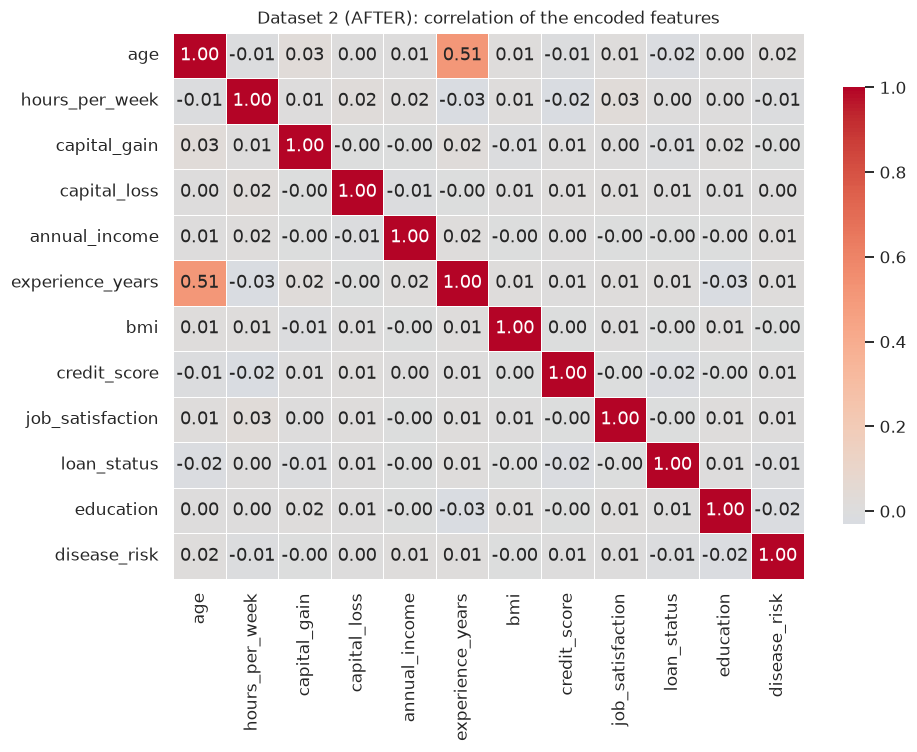

features most correlated with disease_risk:
marital_status_Single           0.024
age                             0.016
annual_income                   0.014
experience_years                0.012
workclass_Self-Employed         0.012
marital_status_Married         -0.039
occupation_Tech-support        -0.017
education                      -0.017
gender_Male                    -0.017
occupation_Machine-op-inspct   -0.014


In [30]:
# --- correlation after encoding and scaling ----------------------------------
plot_correlation(df2_clean, scale_cols + ["job_satisfaction", "loan_status", "education", TARGET],
                 "Dataset 2 (AFTER): correlation of the encoded features", figsize=(9, 7))

print("features most correlated with disease_risk:")
corr_t = df2_clean.corr(numeric_only=True)[TARGET].drop(TARGET)
print(pd.concat([corr_t.nlargest(5), corr_t.nsmallest(5)]).round(3).to_string())

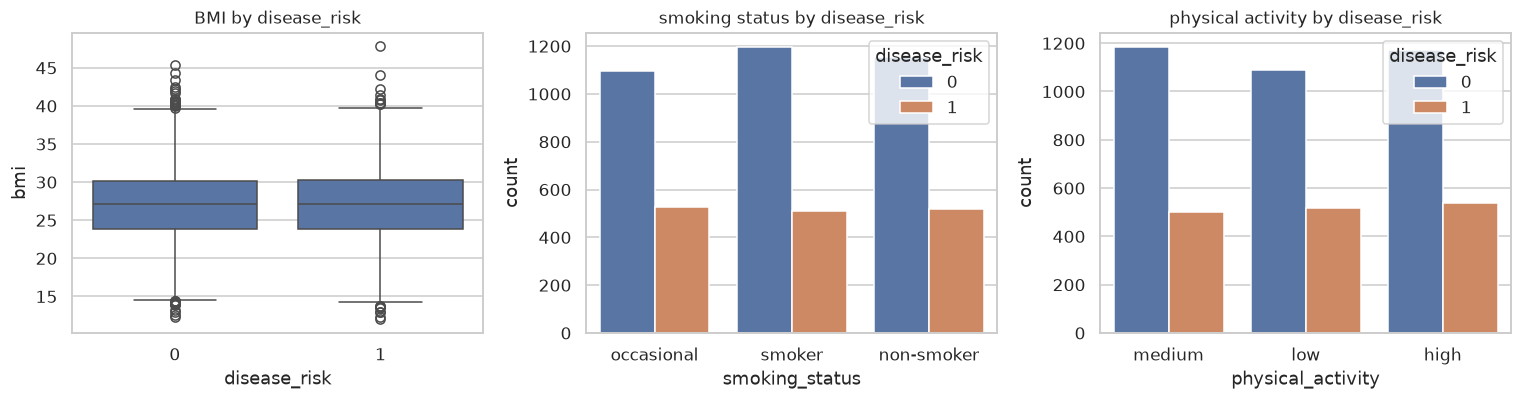

                bmi    age  annual_income  credit_score
disease_risk                                           
0            27.090 43.430     70,382.170       579.600
1            27.060 43.960     71,129.160       581.320


In [31]:
# --- a few relationships with the target, now that the data is usable --------
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.boxplot(data=df2, x=TARGET, y="bmi", ax=axes[0])
axes[0].set_title("BMI by disease_risk")
sns.countplot(data=df2, x="smoking_status", hue=TARGET, ax=axes[1])
axes[1].set_title("smoking status by disease_risk")
sns.countplot(data=df2, x="physical_activity", hue=TARGET, ax=axes[2])
axes[2].set_title("physical activity by disease_risk")
fig.tight_layout()
plt.show()

print(df2.groupby(TARGET)[["bmi", "age", "annual_income", "credit_score"]].mean().round(2).to_string())

In [32]:
# =============================================================================
# PART B - DATASET 1: Census-Income (KDD)
# https://archive.ics.uci.edu/dataset/117/census+income+kdd
# 199523 rows, 40 attributes + a survey weight + the income label. The target
# is whether total person income is above 50k.
#
# The archive is downloaded the first time this cell runs and cached in data/,
# after that the local copy is used.
# =============================================================================

import io, tarfile, zipfile, urllib.request

DATA_DIR = "data"
DATA_FILE = os.path.join(DATA_DIR, "census-income.data")
URL = "https://archive.ics.uci.edu/static/public/117/census+income+kdd.zip"

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(DATA_FILE):
    print("downloading census-income (kdd) from UCI ...")
    raw = urllib.request.urlopen(URL, timeout=180).read()
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        with z.open("census.tar.gz") as tgz, tarfile.open(fileobj=io.BytesIO(tgz.read())) as tar:
            tar.extractall(DATA_DIR)
    print("extracted into", DATA_DIR)
print("using:", DATA_FILE, f"({os.path.getsize(DATA_FILE)/1e6:.0f} MB)")

using: data/census-income.data (104 MB)


In [33]:
# The file has no header row. The names below come from census-income.names,
# which is included in the same archive.
CENSUS_COLS = [
    "age", "class_of_worker", "industry_code", "occupation_code", "education",
    "wage_per_hour", "enrolled_edu_last_wk", "marital_status", "major_industry",
    "major_occupation", "race", "hispanic_origin", "sex", "labor_union",
    "unemployment_reason", "employment_stat", "capital_gains", "capital_losses",
    "dividends", "tax_filer_stat", "prev_residence_region", "prev_residence_state",
    "household_family_stat", "household_summary", "instance_weight", "migration_msa",
    "migration_reg", "migration_within_reg", "live_here_1yr", "migration_sunbelt",
    "num_persons_worked", "family_under_18", "father_birth_country", "mother_birth_country",
    "birth_country", "citizenship", "own_business", "vet_questionnaire", "vet_benefits",
    "weeks_worked", "year", "income_label",
]

# '?' is deliberately not declared as a missing marker here, so that the EDA
# below shows the file the way it is actually distributed.
df1_raw = pd.read_csv(DATA_FILE, header=None, names=CENSUS_COLS, skipinitialspace=True)
print("raw shape:", df1_raw.shape)
df1_raw.head()

raw shape: (199523, 42)


,age,class_of_worker,industry_code,occupation_code,education,wage_per_hour,enrolled_edu_last_wk,marital_status,major_industry,major_occupation,race,hispanic_origin,sex,labor_union,unemployment_reason,employment_stat,capital_gains,capital_losses,dividends,tax_filer_stat,prev_residence_region,prev_residence_state,household_family_stat,household_summary,instance_weight,migration_msa,migration_reg,migration_within_reg,live_here_1yr,migration_sunbelt,num_persons_worked,family_under_18,father_birth_country,mother_birth_country,birth_country,citizenship,own_business,vet_questionnaire,vet_benefits,weeks_worked,year,income_label
0,73,Not in universe,0,0,High school graduate,0,Not in universe,Widowed,Not in universe or children,Not in universe,White,All other,Female,Not in universe,Not in universe,Not in labor force,0,0,0,Nonfiler,Not in universe,Not in universe,Other Rel 18+ ever marr not in subfamily,Other relative of householder,"1,700.090",?,?,?,Not in universe under 1 year old,?,0,Not in universe,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,0,95,- 50000.
1,58,Self-employed-not incorporated,4,34,Some college but no degree,0,Not in universe,Divorced,Construction,Precision production craft & repair,White,All other,Male,Not in universe,Not in universe,Children or Armed Forces,0,0,0,Head of household,South,Arkansas,Householder,Householder,"1,053.550",MSA to MSA,Same county,Same county,No,Yes,1,Not in universe,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,2,52,94,- 50000.
2,18,Not in universe,0,0,10th grade,0,High school,Never married,Not in universe or children,Not in universe,Asian or Pacific Islander,All other,Female,Not in universe,Not in universe,Not in labor force,0,0,0,Nonfiler,Not in universe,Not in universe,Child 18+ never marr Not in a subfamily,Child 18 or older,991.950,?,?,?,Not in universe under 1 year old,?,0,Not in universe,Vietnam,Vietnam,Vietnam,Foreign born- Not a citizen of U S,0,Not in universe,2,0,95,- 50000.
3,9,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,White,All other,Female,Not in universe,Not in universe,Children or Armed Forces,0,0,0,Nonfiler,Not in universe,Not in universe,Child <18 never marr not in subfamily,Child under 18 never married,"1,758.140",Nonmover,Nonmover,Nonmover,Yes,Not in universe,0,Both parents present,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,0,0,94,- 50000.
4,10,Not in universe,0,0,Children,0,Not in universe,Never married,Not in universe or children,Not in universe,White,All other,Female,Not in universe,Not in universe,Children or Armed Forces,0,0,0,Nonfiler,Not in universe,Not in universe,Child <18 never marr not in subfamily,Child under 18 never married,"1,069.160",Nonmover,Nonmover,Nonmover,Yes,Not in universe,0,Both parents present,United-States,United-States,United-States,Native- Born in the United States,0,Not in universe,0,0,94,- 50000.


In [34]:
# --- B.1 EDA BEFORE CLEANING: structure --------------------------------------
df1_raw.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 199523 entries, 0 to 199522
Data columns (total 42 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   age                    199523 non-null  int64  
 1   class_of_worker        199523 non-null  str    
 2   industry_code          199523 non-null  int64  
 3   occupation_code        199523 non-null  int64  
 4   education              199523 non-null  str    
 5   wage_per_hour          199523 non-null  int64  
 6   enrolled_edu_last_wk   199523 non-null  str    
 7   marital_status         199523 non-null  str    
 8   major_industry         199523 non-null  str    
 9   major_occupation       199523 non-null  str    
 10  race                   199523 non-null  str    
 11  hispanic_origin        198649 non-null  str    
 12  sex                    199523 non-null  str    
 13  labor_union            199523 non-null  str    
 14  unemployment_reason    199523 non-null  str    

In [35]:
quality_overview(df1_raw, "Dataset 1 - RAW")

,Dataset 1 - RAW
rows,"199,523.000"
columns,42.000
numeric_columns,13.000
categorical_columns,29.000
duplicate_rows,"3,229.000"
cells_missing,874.000
pct_cells_missing,0.010
memory_MB,387.100


In [36]:
# --- B.2 missing values, which pandas does not see ---------------------------
print("NaN cells reported by pandas:", int(df1_raw.isna().sum().sum()))
print("and even those are a trap:")
print(df1_raw.isna().sum()[lambda s: s > 0].to_string())
print("hispanic_origin has a valid level written as 'NA' (see census-income.names),")
print("which pandas converts to NaN by default.\n")

# The real missing values are hidden behind two string codes.
hidden = {}
for c in categorical_cols(df1_raw):
    s = df1_raw[c].astype("object").str.strip()
    hidden[c] = {"'?'": int((s == "?").sum()),
                 "'Not in universe*'": int(s.str.startswith("Not in universe").sum())}
hidden = pd.DataFrame(hidden).T
hidden["pct_hidden"] = (100 * hidden.sum(axis=1) / len(df1_raw)).round(2)
display(hidden[hidden.sum(axis=1) > 0].sort_values("pct_hidden", ascending=False))

NaN cells reported by pandas: 874
and even those are a trap:
hispanic_origin    874
hispanic_origin has a valid level written as 'NA' (see census-income.names),
which pandas converts to NaN by default.



,'?','Not in universe*',pct_hidden
vet_questionnaire,0,197539,99.010
unemployment_reason,0,193453,96.960
enrolled_edu_last_wk,0,186943,93.690
prev_residence_state,708,183750,92.450
migration_sunbelt,99696,84054,92.090
prev_residence_region,0,183750,92.090
labor_union,0,180459,90.450
family_under_18,0,144232,72.290
migration_within_reg,99696,1516,50.730
migration_msa,99696,1516,50.730


In [37]:
# --- B.3 summary statistics, numeric columns ---------------------------------
numeric_summary(df1_raw)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,"199,523.000",34.494,22.311,0.000,15.000,33.000,50.000,90.000,0.373,-0.733
industry_code,"199,523.000",15.352,18.067,0.000,0.000,0.000,33.000,51.000,0.517,-1.501
occupation_code,"199,523.000",11.307,14.454,0.000,0.000,0.000,26.000,46.000,0.829,-0.897
wage_per_hour,"199,523.000",55.427,274.896,0.000,0.000,0.000,0.000,"9,999.000",8.935,155.219
capital_gains,"199,523.000",434.719,"4,697.531",0.000,0.000,0.000,0.000,"99,999.000",18.991,393.063
capital_losses,"199,523.000",37.314,271.896,0.000,0.000,0.000,0.000,"4,608.000",7.633,61.633
dividends,"199,523.000",197.530,"1,984.164",0.000,0.000,0.000,0.000,"99,999.000",27.787,"1,090.564"
instance_weight,"199,523.000","1,740.380",993.768,37.870,"1,061.615","1,618.310","2,188.610","18,656.300",1.433,5.413
num_persons_worked,"199,523.000",1.956,2.365,0.000,0.000,1.000,4.000,6.000,0.752,-1.082
own_business,"199,523.000",0.175,0.554,0.000,0.000,0.000,0.000,2.000,2.913,6.622


In [38]:
# --- B.4 summary statistics, categorical columns -----------------------------
cat1 = categorical_cols(df1_raw)
pd.DataFrame({
    "n_unique": df1_raw[cat1].nunique(),
    "top_value": [df1_raw[c].mode().iloc[0] for c in cat1],
    "top_freq_pct": [round(100 * df1_raw[c].value_counts(normalize=True).iloc[0], 1) for c in cat1],
}).sort_values("n_unique", ascending=False)

,n_unique,top_value,top_freq_pct
prev_residence_state,51,Not in universe,92.100
mother_birth_country,43,United-States,80.400
father_birth_country,43,United-States,79.800
birth_country,43,United-States,88.700
household_family_stat,38,Householder,26.700
major_industry,24,Not in universe or children,50.500
education,17,High school graduate,24.300
major_occupation,15,Not in universe,50.500
migration_within_reg,10,?,50.000
migration_msa,10,?,50.000


income_label
- 50000.    187141
50000+.      12382

minority class: 6.21 %


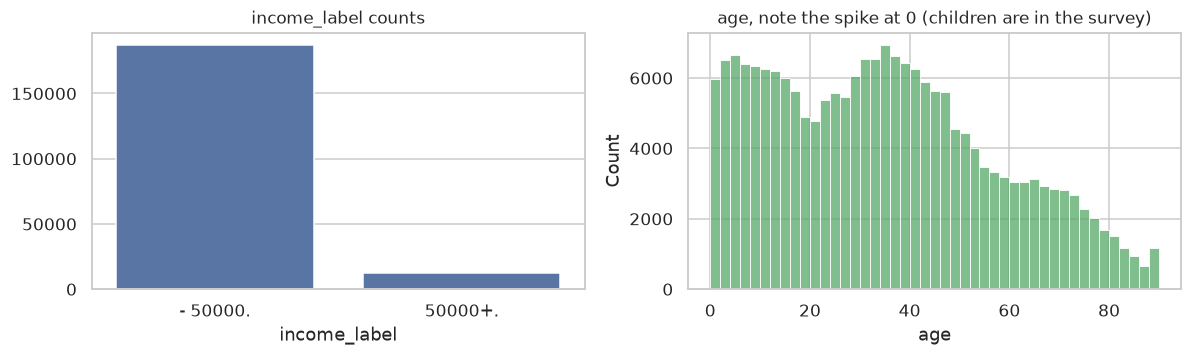

In [39]:
# --- B.5 the target is very imbalanced ---------------------------------------
tgt = df1_raw["income_label"].value_counts()
print(tgt.to_string())
print("\nminority class:", round(100 * tgt.min() / tgt.sum(), 2), "%")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sns.barplot(x=tgt.index.astype(str), y=tgt.values, ax=axes[0], color="#4C72B0")
axes[0].set_title("income_label counts")
sns.histplot(df1_raw["age"], bins=45, ax=axes[1], color="#55A868")
axes[1].set_title("age, note the spike at 0 (children are in the survey)")
fig.tight_layout()
plt.show()

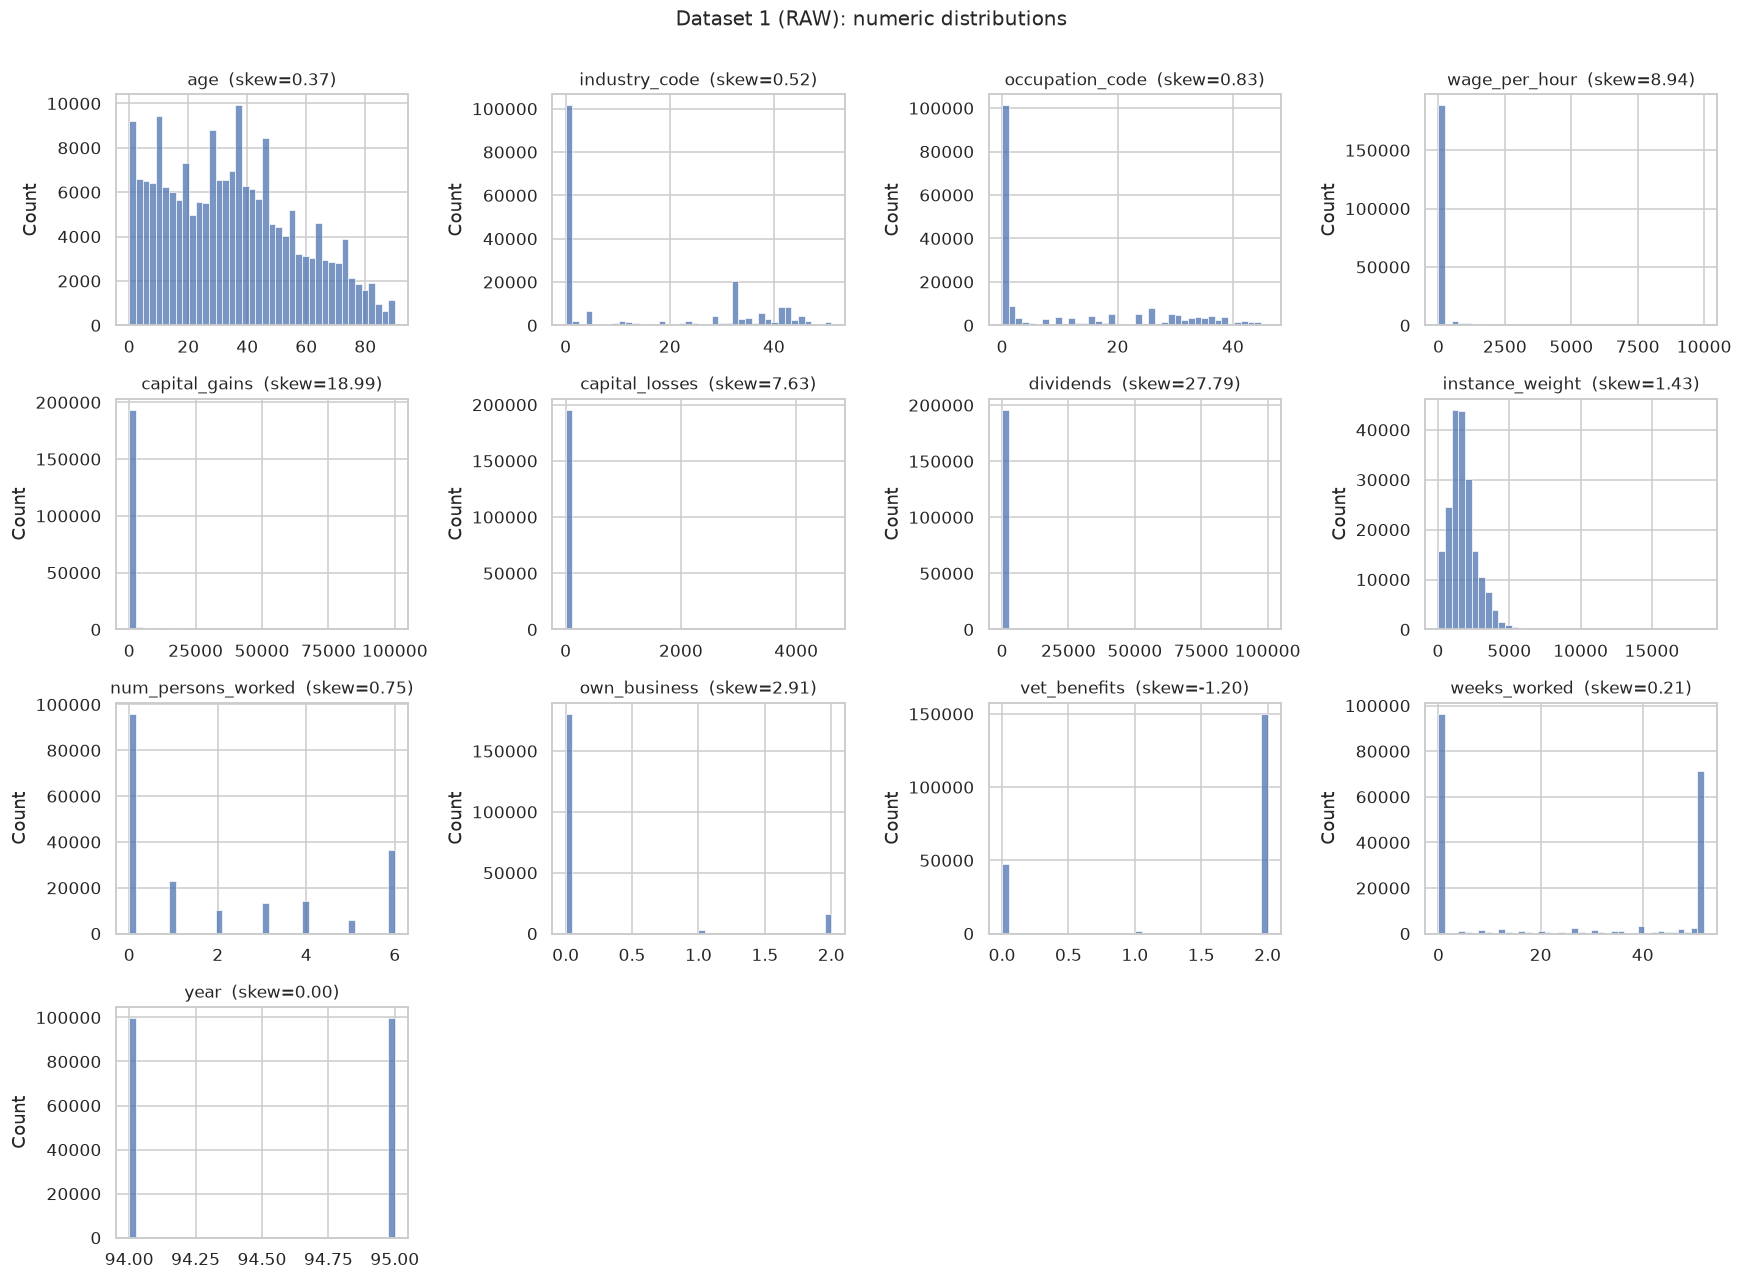

In [40]:
# --- B.6 distribution plots --------------------------------------------------
num1_raw = numeric_cols(df1_raw)
plot_numeric_distributions(df1_raw, num1_raw, "Dataset 1 (RAW): numeric distributions",
                           bins=40, kde=False)

In [41]:
# --- B.7 the money columns are mostly zeros ----------------------------------
money = ["wage_per_hour", "capital_gains", "capital_losses", "dividends"]
pd.DataFrame({
    "pct_zero": (100 * (df1_raw[money] == 0).mean()).round(2),
    "max": df1_raw[money].max(),
    "skew": df1_raw[money].skew().round(1),
})

,pct_zero,max,skew
wage_per_hour,94.330,9999,8.900
capital_gains,96.300,99999,19.000
capital_losses,98.040,4608,7.600
dividends,89.400,99999,27.800


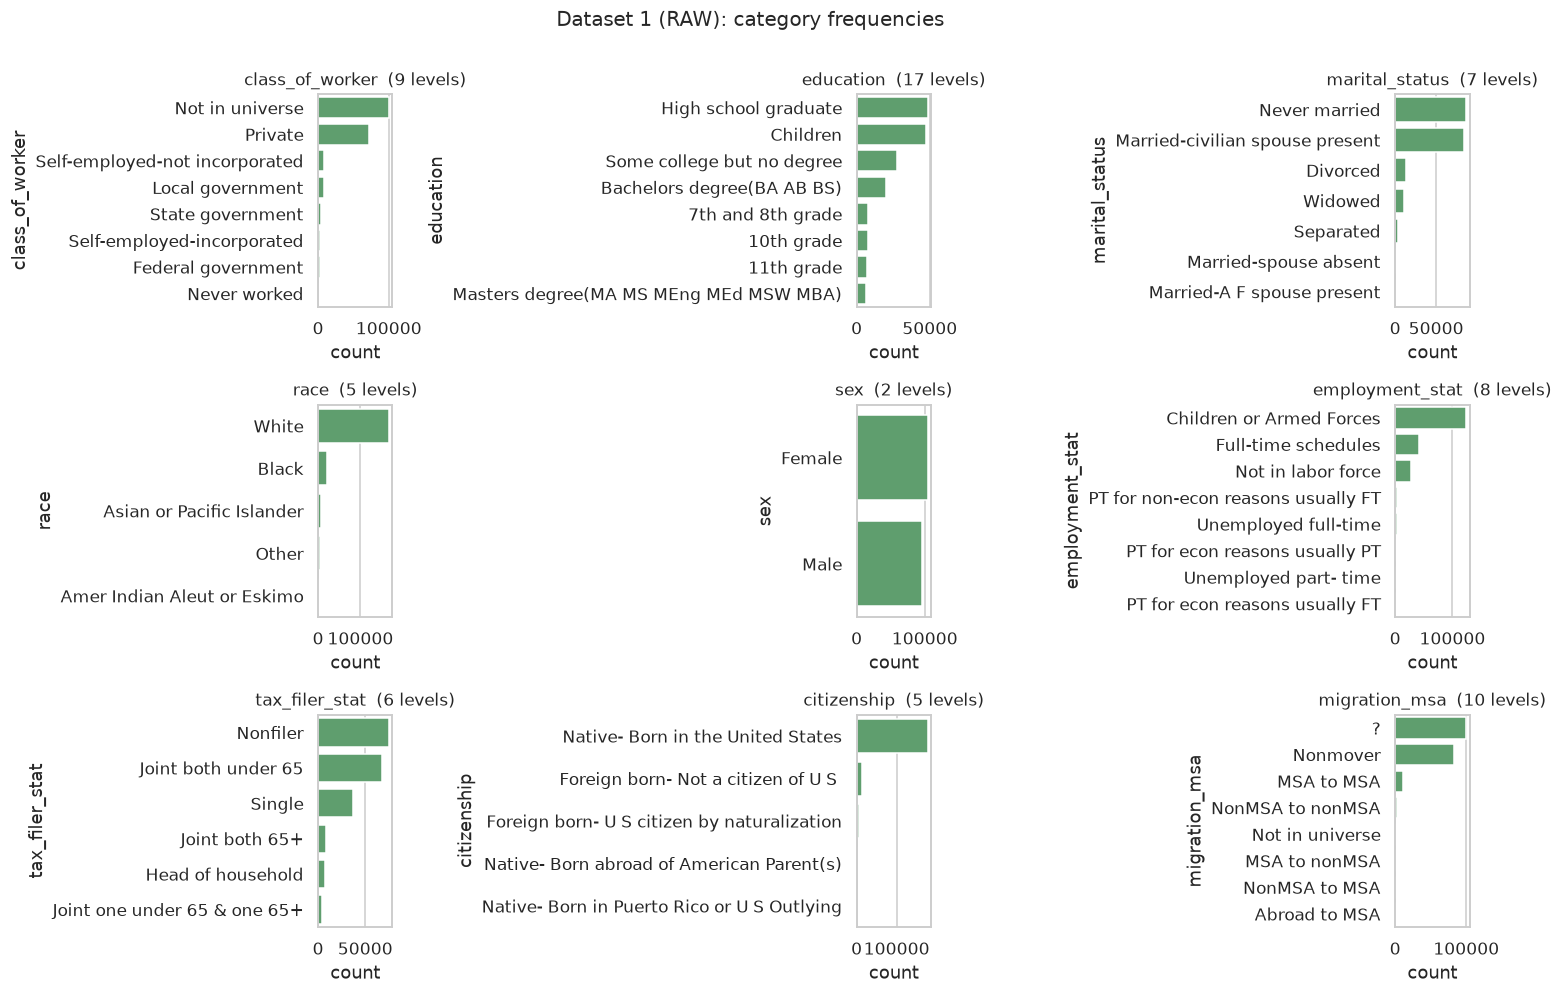

In [42]:
# --- B.8 category frequencies ------------------------------------------------
plot_categorical_counts(df1_raw, ["class_of_worker", "education", "marital_status", "race",
                                  "sex", "employment_stat", "tax_filer_stat", "citizenship",
                                  "migration_msa"],
                        "Dataset 1 (RAW): category frequencies", top=8)

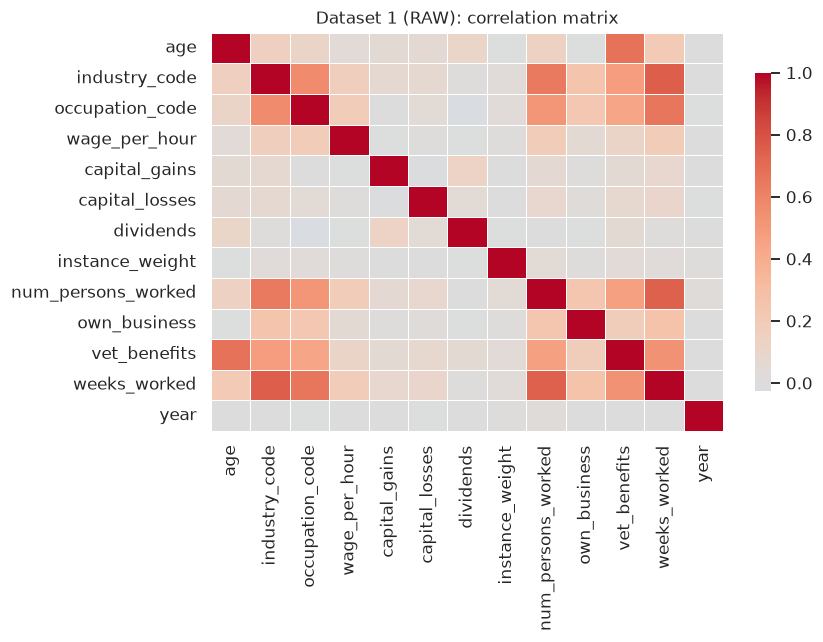

In [43]:
# --- B.9 correlation of the raw numeric columns ------------------------------
plot_correlation(df1_raw, num1_raw, "Dataset 1 (RAW): correlation matrix", figsize=(8, 6))

In [44]:
# =============================================================================
# B.10 ISSUES FOUND IN DATASET 1  (Task 1, part 1)
#
#  1. No header row and no self explaining schema. The column names had to be
#     taken from census-income.names.
#  2. Missing values are written as "?", 415717 cells in total. The four
#     migration columns are about half empty.
#     -> "?" becomes NaN, columns with 40% or more missing are dropped, the
#        rest is imputed
#  3. 13 columns are dominated by "Not in universe", which is not a missing
#     value: it means the question did not apply to that person. It is kept as
#     a normal category, since dropping or imputing it would destroy that
#     information.
#  4. Some labels carry leading or trailing spaces, for example
#     "Handlers equip cleaners etc ". -> strip every text column
#  5. 3229 rows are exact duplicates, and 46627 once instance_weight is left
#     out of the comparison. The documentation quotes 46716.
#     -> drop duplicates
#  6. instance_weight is the survey weight, it describes how many people in the
#     population the row stands for. The documentation says it must not be used
#     as a feature. -> drop it
#  7. industry_code, occupation_code, own_business, vet_benefits and year are
#     stored as integers but they are nominal codes. A model would read code 44
#     as bigger than code 2. -> treat as categorical
#  8. wage_per_hour, capital_gains, capital_losses and dividends are 89% to 98%
#     zeros and heavily skewed. -> log1p plus a 0/1 "has value" column
#  9. Several columns have very many levels (states 51, birth countries 43
#     each, household_family_stat 38). One-hot would add around 220 sparse
#     columns. -> frequency encoding for those
# 10. Scales are very different (age 0-90, dividends 0-99999). -> standardise
# 11. The target is 93.8% / 6.2%. Predicting "everyone earns less than 50k"
#     would already be 93.8% accurate, so accuracy is the wrong metric here.
# 12. income_label is text with a trailing dot: "- 50000." and "50000+.".
#     -> map to 0 and 1
# 13. Children are part of the survey, so age can be 0 and education can be
#     "Children". -> kept, with an is_minor flag
#
# Evidence below.
# =============================================================================

print("2) '?' per column:")
q = {c: int((df1_raw[c].astype('object').str.strip() == '?').sum()) for c in cat1}
print(pd.Series({k: v for k, v in q.items() if v}).sort_values(ascending=False).to_string())

print("\n3) share of 'Not in universe', top 6 columns:")
nu = pd.Series({c: round(100 * df1_raw[c].astype('object').str.strip()
                         .str.startswith('Not in universe').mean(), 1) for c in cat1})
print(nu[nu > 0].sort_values(ascending=False).head(6).to_string())

print("\n5) duplicates: exact rows =", int(df1_raw.duplicated().sum()),
      ", ignoring instance_weight =", int(df1_raw.drop(columns=['instance_weight']).duplicated().sum()))

print("\n7) distinct values of the code columns:")
print(df1_raw[["industry_code", "occupation_code", "own_business", "vet_benefits", "year"]]
      .nunique().to_string())

print("\n8) share of zeros in the money columns:")
print((100 * (df1_raw[money] == 0).mean()).round(1).to_string())

print("\n11) class balance:", (df1_raw['income_label'].value_counts(normalize=True) * 100).round(2).to_dict())
print("13) rows with age < 18:", int((df1_raw['age'] < 18).sum()))

2) '?' per column:


migration_msa           99696
migration_reg           99696
migration_within_reg    99696
migration_sunbelt       99696
father_birth_country     6713
mother_birth_country     6119
birth_country            3393
prev_residence_state      708

3) share of 'Not in universe', top 6 columns:


vet_questionnaire       99.000
unemployment_reason     97.000
enrolled_edu_last_wk    93.700
prev_residence_state    92.100
prev_residence_region   92.100
labor_union             90.400



5) duplicates: exact rows = 3229 , ignoring instance_weight = 46627

7) distinct values of the code columns:
industry_code      52
occupation_code    47
own_business        3
vet_benefits        3
year                2

8) share of zeros in the money columns:
wage_per_hour    94.300
capital_gains    96.300
capital_losses   98.000
dividends        89.400

11) class balance: {'- 50000.': 93.79, '50000+.': 6.21}
13) rows with age < 18: 55992


In [45]:
# =============================================================================
# B.11 CLEANING DATASET 1  (Task 1, part 2)
# =============================================================================

df1 = df1_raw.copy()
log1 = []


def step1(msg, frame=None):
    shape = f"{frame.shape}" if frame is not None else ""
    log1.append(msg)
    print(f"[{len(log1):02d}] {msg}   {shape}")

In [46]:
# --- step 1: whitespace, '?' to NaN, target to 0/1 ---------------------------
for c in categorical_cols(df1):
    df1[c] = df1[c].astype("object").str.strip()
df1 = df1.replace("?", np.nan)

df1["income_label"] = (df1["income_label"].str.strip(" .") == "50000+").astype(int)
step1("whitespace stripped, '?' to NaN, target encoded as 0/1", df1)
print("missing cells now:", int(df1.isna().sum().sum()))
print("target balance   :", df1["income_label"].value_counts(normalize=True).round(4).to_dict())

[01] whitespace stripped, '?' to NaN, target encoded as 0/1   (199523, 42)
missing cells now: 416591
target balance   : {0: 0.9379, 1: 0.0621}


In [47]:
# --- step 2: drop the survey weight and the duplicate records ----------------
df1 = df1.drop(columns=["instance_weight"])
before = len(df1)
df1 = df1.drop_duplicates(keep="first")
step1(f"dropped instance_weight and {before - len(df1):,} duplicate records", df1)

[02] dropped instance_weight and 46,627 duplicate records   (152896, 41)


In [48]:
# --- step 3: columns that are too empty to impute ----------------------------
miss1 = missing_report(df1)
display(miss1[miss1.n_missing > 0])

drop_cols = miss1.index[miss1.pct_missing >= 40].tolist()
df1 = df1.drop(columns=drop_cols)
step1(f"dropped {len(drop_cols)} columns with 40% or more missing: {drop_cols}", df1)

# dropping columns can make rows identical that were different before
before = len(df1)
df1 = df1.drop_duplicates(keep="first")
step1(f"checked duplicates again after the column drop: {before - len(df1):,} more rows removed", df1)

,n_missing,pct_missing,dtype,n_unique
migration_msa,74944,49.020,object,9
migration_reg,74944,49.020,object,8
migration_within_reg,74944,49.020,object,9
migration_sunbelt,74944,49.020,object,3
father_birth_country,6383,4.170,object,42
mother_birth_country,5810,3.800,object,42
birth_country,3322,2.170,object,42
hispanic_origin,848,0.550,object,9
prev_residence_state,698,0.460,object,50


[03] dropped 4 columns with 40% or more missing: ['migration_msa', 'migration_reg', 'migration_within_reg', 'migration_sunbelt']   (152896, 37)
[04] checked duplicates again after the column drop: 528 more rows removed   (152368, 37)


In [49]:
# --- step 4: impute what is left ---------------------------------------------
# Everything still missing is categorical (birth countries, state, hispanic
# origin). Mode imputation, but the fact that the answer was missing is kept in
# a separate 0/1 column instead of being thrown away.
cat_na = [c for c in categorical_cols(df1) if df1[c].isna().any()]
print("columns to impute:", {c: int(df1[c].isna().sum()) for c in cat_na})

for c in cat_na:
    df1[c + "_was_missing"] = df1[c].isna().astype(int)
    df1[c] = df1[c].fillna(df1[c].mode().iloc[0])

step1(f"mode imputed {len(cat_na)} categorical columns and added missing flags", df1)
print("missing cells left:", int(df1.isna().sum().sum()))

columns to impute: {'hispanic_origin': 848, 'prev_residence_state': 669, 'father_birth_country': 6383, 'mother_birth_country': 5810, 'birth_country': 3322}


[05] mode imputed 5 categorical columns and added missing flags   (152368, 42)
missing cells left: 0


In [50]:
# --- step 5: the numeric columns that are really nominal codes ---------------
CODE_COLS = ["industry_code", "occupation_code", "own_business", "vet_benefits", "year"]
for c in CODE_COLS:
    df1[c] = df1[c].astype(str)
step1("industry/occupation/own_business/vet_benefits/year treated as categorical", df1)

[06] industry/occupation/own_business/vet_benefits/year treated as categorical   (152368, 42)


In [51]:
# --- step 6: skew of the money columns ---------------------------------------
for c in money:
    df1["has_" + c] = (df1[c] > 0).astype(int)   # keeps the zero / non zero split
    df1[c] = np.log1p(df1[c])

df1["is_minor"] = (df1["age"] < 18).astype(int)

print("skew after log1p:")
print(df1[money].skew().round(2).to_string())
step1("log1p applied to the 4 money columns, presence flags and is_minor added", df1)

skew after log1p:
wage_per_hour    3.290
capital_gains    4.320
capital_losses   6.020
dividends        2.600
[07] log1p applied to the 4 money columns, presence flags and is_minor added   (152368, 47)


In [52]:
# --- step 7: encoding --------------------------------------------------------
# ordinal   -> education, 17 levels from Children up to Doctorate
# binary    -> sex, and the target which is already 0/1
# one-hot   -> every remaining categorical with 10 levels or fewer, stored as
#              int8 to keep the memory down on a 150k row table
# frequency -> everything above 10 levels. One-hot there would add around 220
#              almost empty columns. Frequency encoding puts it in one column
#              and, unlike target encoding, it does not leak the label.

EDU_ORDER = ["Children", "Less than 1st grade", "1st 2nd 3rd or 4th grade", "5th or 6th grade",
             "7th and 8th grade", "9th grade", "10th grade", "11th grade",
             "12th grade no diploma", "High school graduate", "Some college but no degree",
             "Associates degree-occup /vocational", "Associates degree-academic program",
             "Bachelors degree(BA AB BS)", "Masters degree(MA MS MEng MEd MSW MBA)",
             "Prof school degree (MD DDS DVM LLB JD)", "Doctorate degree(PhD EdD)"]
assert set(EDU_ORDER) == set(df1["education"].unique()), "education levels do not match"

df1_enc = df1.copy()
df1_enc["education"] = df1_enc["education"].map({lvl: i for i, lvl in enumerate(EDU_ORDER)}).astype(int)
df1_enc["sex"] = (df1_enc["sex"] == "Male").astype(int)
print("ordinal : education, 0 = Children ... 16 = Doctorate")
print("binary  : sex (Female=0, Male=1), income_label (<=50k=0, >50k=1)")

card = df1_enc[categorical_cols(df1_enc)].nunique().sort_values(ascending=False)
high_card = card[card > 10].index.tolist()
low_card = card[card <= 10].index.tolist()
print("\nfrequency encoded:", high_card)
print("one-hot encoded  :", len(low_card), "columns")

for c in high_card:
    freq = df1_enc[c].value_counts(normalize=True)
    df1_enc[c + "_freq"] = df1_enc[c].map(freq).astype("float32")
df1_enc = df1_enc.drop(columns=high_card)

df1_enc = pd.get_dummies(df1_enc, columns=low_card, drop_first=True, dtype="int8")
step1(f"encoding done, {df1.shape[1]} columns became {df1_enc.shape[1]}", df1_enc)
df1_enc.iloc[:5, :12]

ordinal : education, 0 = Children ... 16 = Doctorate
binary  : sex (Female=0, Male=1), income_label (<=50k=0, >50k=1)



frequency encoded: ['industry_code', 'prev_residence_state', 'occupation_code', 'father_birth_country', 'mother_birth_country', 'birth_country', 'household_family_stat', 'major_industry', 'major_occupation']
one-hot encoded  : 18 columns


[08] encoding done, 47 columns became 105   (152368, 105)


,age,education,wage_per_hour,sex,capital_gains,capital_losses,dividends,num_persons_worked,weeks_worked,income_label,hispanic_origin_was_missing,prev_residence_state_was_missing
0,73,9,0.000,0,0.000,0.000,0.000,0,0,0,0,0
1,58,10,0.000,1,0.000,0.000,0.000,1,52,0,0,0
2,18,6,0.000,0,0.000,0.000,0.000,0,0,0,0,0
3,9,0,0.000,0,0.000,0.000,0.000,0,0,0,0,0
4,10,0,0.000,0,0.000,0.000,0.000,0,0,0,0,0


In [53]:
# --- step 8: scaling ---------------------------------------------------------
TARGET1 = "income_label"
scale1 = ["age", "wage_per_hour", "capital_gains", "capital_losses", "dividends",
          "num_persons_worked", "weeks_worked", "education"] + [c for c in df1_enc if c.endswith("_freq")]

df1_clean = df1_enc.copy()
df1_clean[scale1] = StandardScaler().fit_transform(df1_clean[scale1]).astype("float32")
step1("continuous and frequency columns standardised", df1_clean)
df1_clean[scale1].describe().T[["mean", "std", "min", "max"]].round(3)

[09] continuous and frequency columns standardised   (152368, 105)


,mean,std,min,max
age,0.000,1.000,-2.033,2.560
wage_per_hour,0.000,1.000,-0.282,4.914
capital_gains,0.000,1.000,-0.224,5.916
capital_losses,-0.000,1.000,-0.162,6.933
dividends,0.000,1.000,-0.373,5.059
num_persons_worked,0.000,1.000,-1.060,1.437
weeks_worked,0.000,1.000,-1.270,0.919
education,-0.000,1.000,-2.263,1.923
industry_code_freq,-0.000,1.000,-0.971,1.325
prev_residence_state_freq,0.000,1.000,-3.131,0.321


In [54]:
# --- the full list of steps applied to dataset 1 -----------------------------
print("Dataset 1 cleaning steps")
print("-" * 60)
for i, m in enumerate(log1, 1):
    print(f"{i:2d}. {m}")
print("-" * 60)
print(f"raw   : {df1_raw.shape[0]:,} rows x {df1_raw.shape[1]:3d} cols  "
      f"({df1_raw.memory_usage(deep=True).sum()/1e6:,.0f} MB)")
print(f"clean : {df1_clean.shape[0]:,} rows x {df1_clean.shape[1]:3d} cols  "
      f"({df1_clean.memory_usage(deep=True).sum()/1e6:,.0f} MB)")

Dataset 1 cleaning steps
------------------------------------------------------------
 1. whitespace stripped, '?' to NaN, target encoded as 0/1
 2. dropped instance_weight and 46,627 duplicate records
 3. dropped 4 columns with 40% or more missing: ['migration_msa', 'migration_reg', 'migration_within_reg', 'migration_sunbelt']
 4. checked duplicates again after the column drop: 528 more rows removed
 5. mode imputed 5 categorical columns and added missing flags
 6. industry/occupation/own_business/vet_benefits/year treated as categorical
 7. log1p applied to the 4 money columns, presence flags and is_minor added
 8. encoding done, 47 columns became 105
 9. continuous and frequency columns standardised
------------------------------------------------------------


raw   : 199,523 rows x  42 cols  (387 MB)
clean : 152,368 rows x 105 cols  (38 MB)


In [55]:
# =============================================================================
# B.12 EDA AFTER CLEANING AND COMPARISON  (Task 2)
# =============================================================================

cmp1 = pd.concat([quality_overview(df1_raw, "BEFORE"),
                  quality_overview(df1_clean, "AFTER")], axis=1)
cmp1["change"] = cmp1["AFTER"] - cmp1["BEFORE"]
cmp1

,BEFORE,AFTER,change
rows,"199,523.000","152,368.000","-47,155.000"
columns,42.000,105.000,63.000
numeric_columns,13.000,105.000,92.000
categorical_columns,29.000,0.000,-29.000
duplicate_rows,"3,229.000",0.000,"-3,229.000"
cells_missing,874.000,0.000,-874.000
pct_cells_missing,0.010,0.000,-0.010
memory_MB,387.100,37.800,-349.300


In [56]:
# --- the hidden missing values are gone --------------------------------------
q_after = sum(int((df1_clean[c].astype('object') == '?').sum()) for c in categorical_cols(df1_clean))
print("'?' cells      before:", sum(q.values()), " after:", q_after)
print("NaN cells      before:", int(df1_raw.isna().sum().sum()),
      "(the 'NA' hispanic_origin level)  after:", int(df1_clean.isna().sum().sum()))
print("duplicate rows before:", int(df1_raw.drop(columns=['instance_weight']).duplicated().sum()),
      " after:", int(df1_clean.duplicated().sum()))
print("text columns   before:", len(categorical_cols(df1_raw)),
      " after:", len(categorical_cols(df1_clean)))

'?' cells      before: 415717  after: 0
NaN cells      before: 874 (the 'NA' hispanic_origin level)  after: 0


duplicate rows before: 46627  after: 0
text columns   before: 29  after: 0


In [57]:
# --- summary statistics after cleaning ---------------------------------------
numeric_summary(df1, ["age", "wage_per_hour", "capital_gains", "capital_losses",
                      "dividends", "num_persons_worked", "weeks_worked"])

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,"152,368.000",39.835,19.596,0.000,26.000,38.000,53.000,90.000,0.306,-0.426
wage_per_hour,"152,368.000",0.500,1.773,0.000,0.000,0.000,0.000,9.210,3.286,8.896
capital_gains,"152,368.000",0.420,1.875,0.000,0.000,0.000,0.000,11.513,4.320,17.041
capital_losses,"152,368.000",0.193,1.189,0.000,0.000,0.000,0.000,8.436,6.017,34.257
dividends,"152,368.000",0.790,2.120,0.000,0.000,0.000,0.000,11.513,2.597,5.496
num_persons_worked,"152,368.000",2.547,2.403,0.000,0.000,2.000,5.000,6.000,0.342,-1.495
weeks_worked,"152,368.000",30.166,23.762,0.000,0.000,46.000,52.000,52.000,-0.332,-1.762


,skew_before,skew_after,kurtosis_before,kurtosis_after
wage_per_hour,8.940,3.290,155.220,8.900
capital_gains,18.990,4.320,393.060,17.040
capital_losses,7.630,6.020,61.630,34.260
dividends,27.790,2.600,"1,090.560",5.500


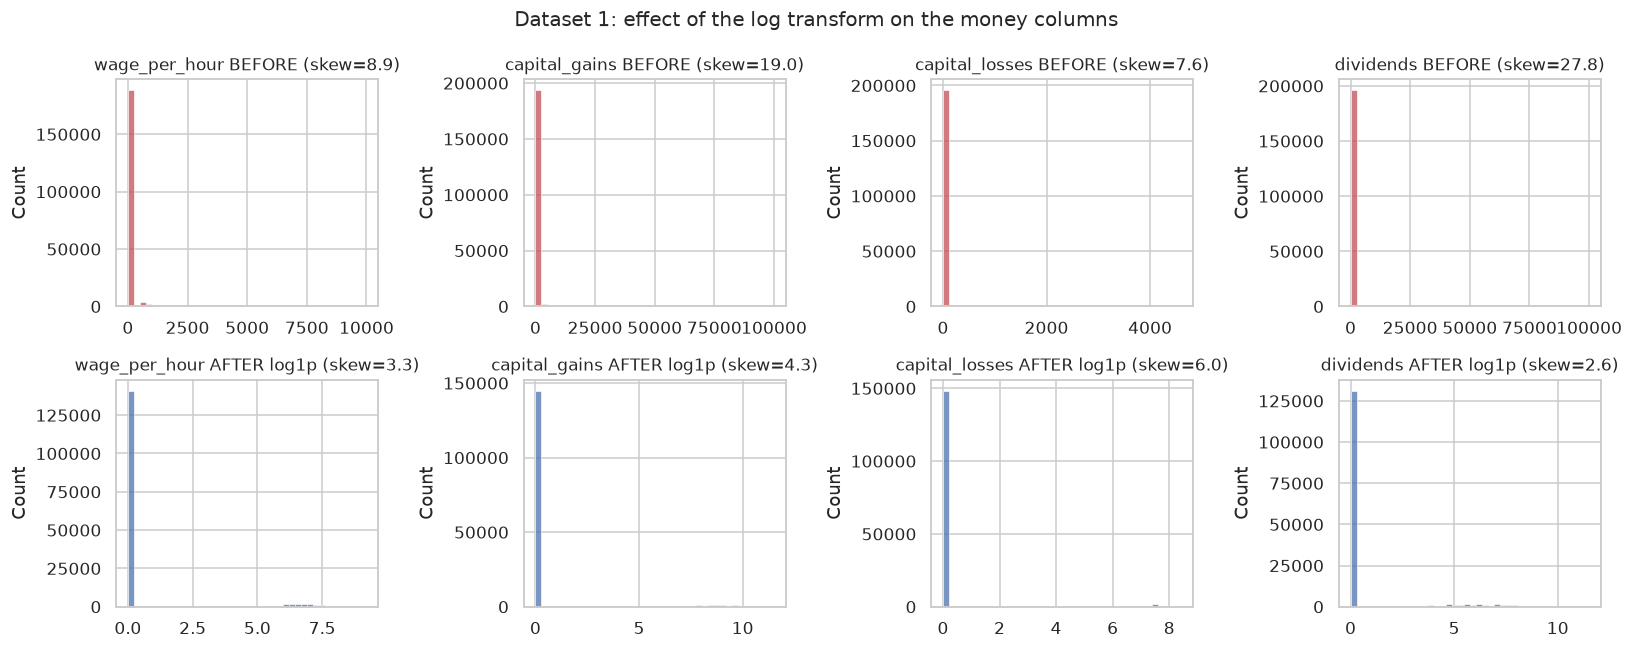

In [58]:
# --- skew and kurtosis before and after the log transform --------------------
skew_cmp = pd.DataFrame({
    "skew_before": df1_raw[money].skew(),
    "skew_after": df1[money].skew(),
    "kurtosis_before": df1_raw[money].kurtosis(),
    "kurtosis_after": df1[money].kurtosis(),
}).round(2)
display(skew_cmp)

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for j, c in enumerate(money):
    sns.histplot(df1_raw[c], bins=40, ax=axes[0, j], color="#C44E52")
    axes[0, j].set_title(f"{c} BEFORE (skew={df1_raw[c].skew():.1f})")
    sns.histplot(df1[c], bins=40, ax=axes[1, j], color="#4C72B0")
    axes[1, j].set_title(f"{c} AFTER log1p (skew={df1[c].skew():.1f})")
    axes[0, j].set_xlabel("")
    axes[1, j].set_xlabel("")
fig.suptitle("Dataset 1: effect of the log transform on the money columns", fontsize=13)
fig.tight_layout()
plt.show()

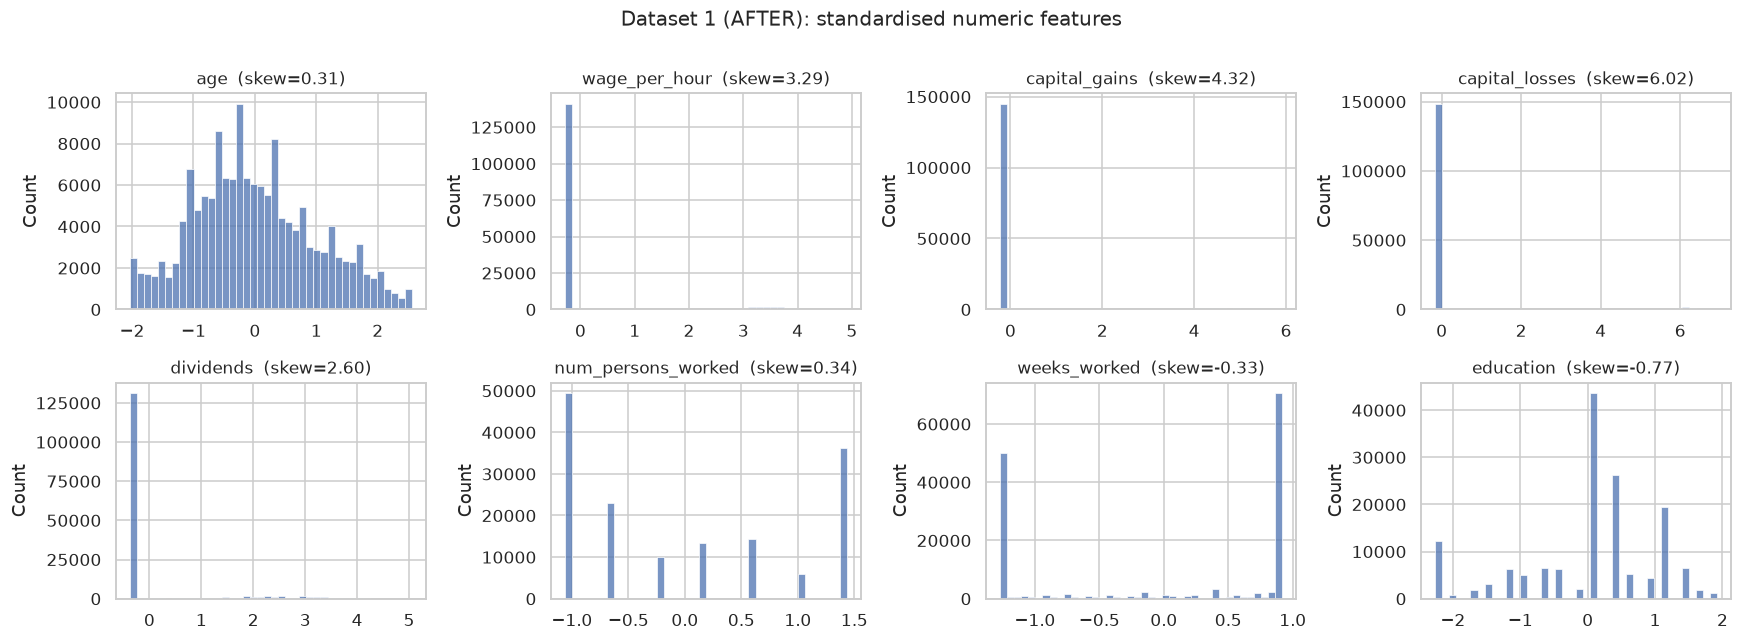

In [59]:
# --- distributions after cleaning --------------------------------------------
plot_numeric_distributions(df1_clean, scale1[:8],
                           "Dataset 1 (AFTER): standardised numeric features", bins=40, kde=False)

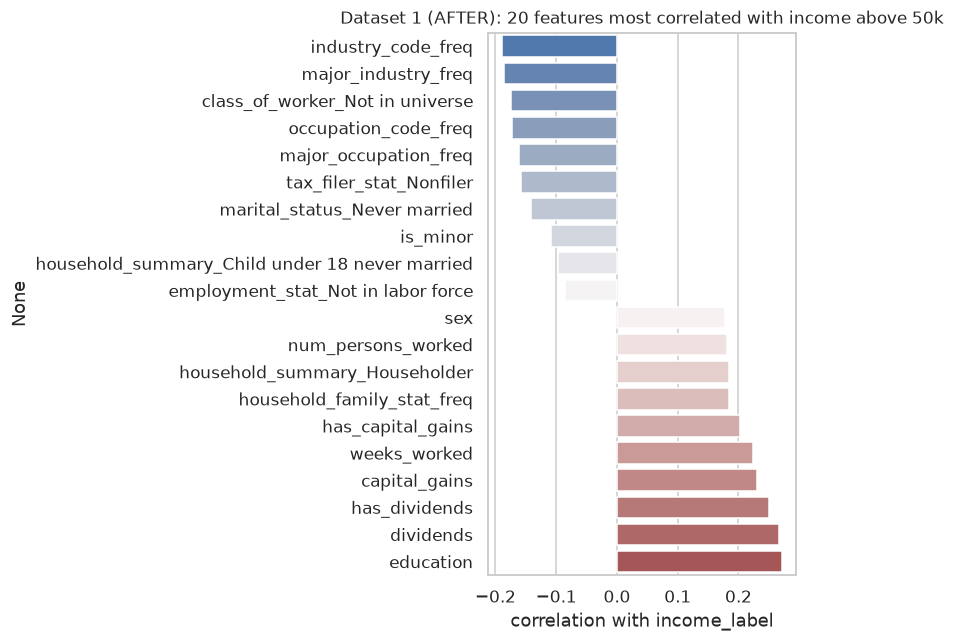

,corr_with_target
industry_code_freq,-0.190
major_industry_freq,-0.185
class_of_worker_Not in universe,-0.174
occupation_code_freq,-0.173
major_occupation_freq,-0.161
tax_filer_stat_Nonfiler,-0.158
marital_status_Never married,-0.142
is_minor,-0.108
household_summary_Child under 18 never married,-0.097
employment_stat_Not in labor force,-0.086


In [60]:
# --- what the cleaned data correlates with -----------------------------------
corr1 = df1_clean.corr(numeric_only=True)[TARGET1].drop(TARGET1).sort_values()
top = pd.concat([corr1.tail(10), corr1.head(10)]).sort_values()
plt.figure(figsize=(7.5, 6))
sns.barplot(x=top.values, y=top.index, palette="vlag", hue=top.index, legend=False)
plt.title("Dataset 1 (AFTER): 20 features most correlated with income above 50k")
plt.xlabel("correlation with income_label")
plt.tight_layout()
plt.show()
top.round(3).to_frame("corr_with_target")

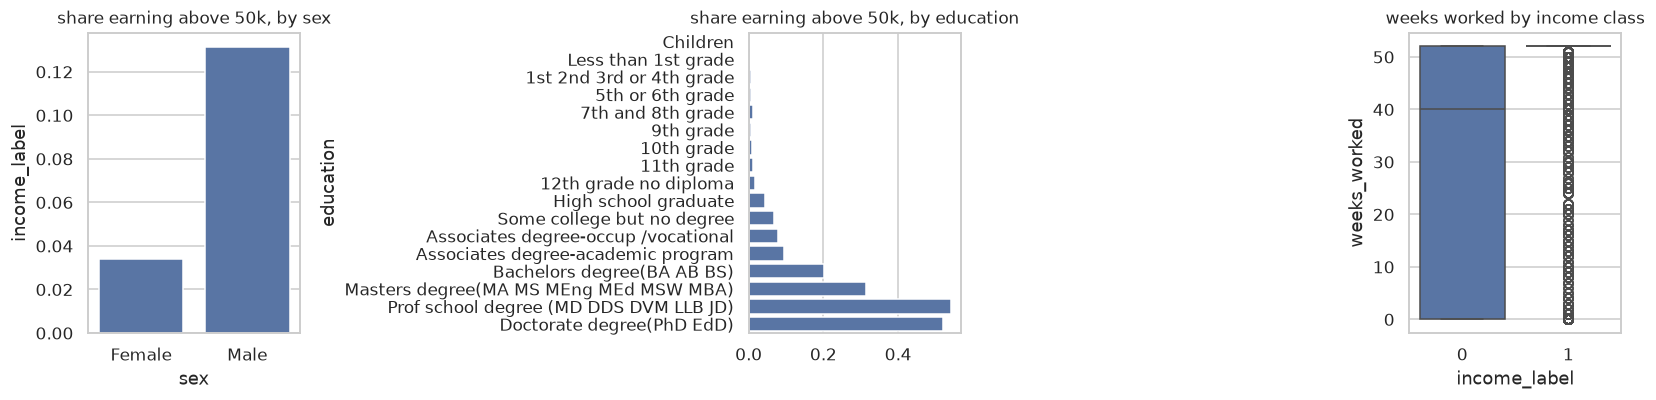

In [61]:
# --- a few readable relationships, taken from the unencoded clean frame ------
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.barplot(data=df1, x="sex", y="income_label", ax=axes[0], errorbar=None)
axes[0].set_title("share earning above 50k, by sex")
edu_rate = df1.groupby("education")["income_label"].mean().reindex(EDU_ORDER)
sns.barplot(x=edu_rate.values, y=edu_rate.index, ax=axes[1], color="#4C72B0")
axes[1].set_title("share earning above 50k, by education")
sns.boxplot(data=df1, x="income_label", y="weeks_worked", ax=axes[2])
axes[2].set_title("weeks worked by income class")
fig.tight_layout()
plt.show()

In [62]:
# =============================================================================
# PART C - BOTH DATASETS, BEFORE AGAINST AFTER
# =============================================================================

summary = pd.concat([
    quality_overview(df1_raw, "D1 before")["D1 before"],
    quality_overview(df1_clean, "D1 after")["D1 after"],
    quality_overview(df2_raw, "D2 before")["D2 before"],
    quality_overview(df2_clean, "D2 after")["D2 after"],
], axis=1)
summary

,D1 before,D1 after,D2 before,D2 after
rows,"199,523.000","152,368.000","5,050.000","5,000.000"
columns,42.000,105.000,20.000,34.000
numeric_columns,13.000,105.000,9.000,34.000
categorical_columns,29.000,0.000,11.000,0.000
duplicate_rows,"3,229.000",0.000,49.000,0.000
cells_missing,874.000,0.000,"1,509.000",0.000
pct_cells_missing,0.010,0.000,1.494,0.000
memory_MB,387.100,37.800,3.400,1.400


In [63]:
# --- what each problem looked like before and after --------------------------
recap = pd.DataFrame([
    {"dataset": "Dataset 1 (census kdd)", "issue": "duplicate records",
     "before": int(df1_raw.drop(columns=['instance_weight']).duplicated().sum()),
     "after": int(df1_clean.duplicated().sum())},
    {"dataset": "Dataset 1 (census kdd)", "issue": "missing values hidden as '?'",
     "before": sum(q.values()), "after": 0},
    {"dataset": "Dataset 1 (census kdd)", "issue": "non numeric columns",
     "before": len(categorical_cols(df1_raw)), "after": len(categorical_cols(df1_clean))},
    {"dataset": "Dataset 1 (census kdd)", "issue": "largest skew of the money columns",
     "before": round(df1_raw[money].skew().abs().max(), 1),
     "after": round(df1[money].skew().abs().max(), 1)},
    {"dataset": "Dataset 2 (attached)", "issue": "duplicate records",
     "before": int(df2_raw.duplicated().sum()), "after": int(df2_clean.duplicated().sum())},
    {"dataset": "Dataset 2 (attached)", "issue": "missing cells including 'unknown'",
     "before": int(df2_raw.isna().sum().sum()) + int((df2_raw == "unknown").sum().sum()),
     "after": int(df2_clean.isna().sum().sum())},
    {"dataset": "Dataset 2 (attached)", "issue": "impossible values",
     "before": int((df2_raw["hours_per_week"] > 168).sum()
                   + ((df2_raw["bmi"] > 60) | (df2_raw["bmi"] < 12)).sum()
                   + (pd.to_numeric(df2_raw["annual_income"], errors="coerce") < 0).sum()),
     "after": 0},
    {"dataset": "Dataset 2 (attached)", "issue": "native_country labels",
     "before": df2_raw["native_country"].nunique(), "after": df2["native_country"].nunique()},
    {"dataset": "Dataset 2 (attached)", "issue": "non numeric columns",
     "before": len(categorical_cols(df2_raw)), "after": len(categorical_cols(df2_clean))},
])
recap

,dataset,issue,before,after
0,Dataset 1 (census kdd),duplicate records,"46,627.000",0.000
1,Dataset 1 (census kdd),missing values hidden as '?',"415,717.000",0.000
2,Dataset 1 (census kdd),non numeric columns,29.000,0.000
3,Dataset 1 (census kdd),largest skew of the money columns,27.800,6.000
4,Dataset 2 (attached),duplicate records,49.000,0.000
5,Dataset 2 (attached),missing cells including 'unknown',"1,711.000",0.000
6,Dataset 2 (attached),impossible values,58.000,0.000
7,Dataset 2 (attached),native_country labels,8.000,6.000
8,Dataset 2 (attached),non numeric columns,11.000,0.000


In [64]:
# --- save the cleaned datasets -----------------------------------------------
os.makedirs("output", exist_ok=True)
df2_clean.to_csv("output/dataset2_attached_clean.csv", index=False)
df1_clean.to_csv("output/dataset1_census_kdd_clean.csv.gz", index=False, compression="gzip")
for f in sorted(os.listdir("output")):
    print(f"{f:40s} {os.path.getsize('output/' + f)/1e6:8.1f} MB")

dataset1_census_kdd_clean.csv.gz              4.1 MB
dataset2_attached_clean.csv                   1.0 MB


In [65]:
# =============================================================================
# CONCLUSION
#
# The two datasets are broken in different ways, and that is what decided the
# treatment in each case.
#
# Dataset 2 is dirty in its values. A single "unknown" string turned two
# numeric columns into text, there were duplicates, one country written three
# ways, and values that cannot exist (391 hours in a week, BMI 204, negative
# salaries, work experience starting before the age of 16). The cleaning had to
# be driven by domain rules: check what is possible first, only then impute,
# and cap the tails at the end.
#
# Dataset 1 has clean values but a difficult structure: no header, missing
# values written as "?", a category that means "question did not apply",
# 46627 duplicates, a survey weight that is not a feature, nominal codes stored
# as integers, money columns that are almost all zeros, and a 94/6 class split.
# Here the work was to read the documentation and decide what each column
# actually is before encoding it.
#
# The encoding was chosen per column, not per dataset: ordinal where a real
# order exists, one column for two level variables, one-hot for short nominal
# lists, and frequency encoding where one-hot would have created around 220
# nearly empty columns.
#
# The EDA before cleaning is what made the issue lists possible in the first
# place, since the dtypes, the missing value counts and the boxplots are what
# exposed the problems. The EDA after cleaning shows no missing cells, no
# duplicates, no text columns, comparable scales, and skew brought down from
# 16.1 to 0.1 for annual_income and from 27.8 to 2.6 for dividends. The shape
# of the honest part of each distribution did not change, which is the sign
# that the cleaning removed noise and not signal.
# =============================================================================
print("done")

done
